

Firefly-Optimized CNN for Fashion-MNIST

In [1]:
import os, sys, platform, time, json, random, shutil, hashlib, pickle
import importlib.metadata as md_
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, roc_auc_score, log_loss
from scipy import stats
from IPython.display import display

SMOKE = False          # True = tiny synthetic run ONLY to test the code (never report its numbers)
USE_DRIVE = False      # True (Colab only) = save outputs + checkpoints to Google Drive

CFG = dict(
    SEEDS=list(range(12)),            # evaluation seeds (final test comparison)
    SELECT_SEEDS=[100, 101, 102],     # re-ranking seeds (disjoint from SEEDS)
    NOISE_SEEDS=[11, 12, 13],         # proxy-noise study seeds
    FA_POP=8, FA_ITERS=6,             # fireflies, generations
    REPEATS=2,                        # independent search replicates (FA and random search each)
    FA_SEEDS=[1, 2, 3], RS_SEEDS=[123, 124, 125], FIT_SEEDS=[42, 43, 44],
    BETA0=1.0, GAMMA=5.0, ALPHA0=0.30, ALPHA_DECAY=0.93,
    SEARCH_N=20000, SEARCH_VAL_N=10000, SEARCH_EPOCHS=12, SEARCH_PATIENCE=3,
    FINAL_EPOCHS=30, FINAL_PATIENCE=4,
    TOP_K_PER_REP=2,                  # finalists per method per replicate
    LAMBDA=0.03,                      # parsimony weight (fixed in V7)
    VAL_N=10000,
    TOY_RUNS=30, TOY_POP=20, TOY_ITERS=99,
    EQUIV_MARGIN_PP=0.5,
)
if SMOKE:
    CFG.update(SEEDS=[0, 1], SELECT_SEEDS=[100], NOISE_SEEDS=[11, 12], FA_POP=4, FA_ITERS=2, REPEATS=2,
               FA_SEEDS=[1, 2], RS_SEEDS=[123, 124], FIT_SEEDS=[42, 43], SEARCH_N=500, SEARCH_VAL_N=500,
               SEARCH_EPOCHS=2, SEARCH_PATIENCE=1, FINAL_EPOCHS=3, FINAL_PATIENCE=1, TOP_K_PER_REP=1,
               VAL_N=500, TOY_RUNS=3, TOY_POP=8, TOY_ITERS=15)

HP_COLS = ["lr", "f1", "f2", "dense", "dropout", "batch", "n_conv", "bn", "flip", "shift", "cosine", "wd"]
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
CODE_VERSION = "v8"

OUT = "results"
if USE_DRIVE and not SMOKE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/firefly_results_v8"
os.makedirs(OUT, exist_ok=True)
CKPT = f"{OUT}/ckpt"; os.makedirs(CKPT, exist_ok=True)

def set_seed(s):
    keras.utils.set_random_seed(s)

def savefig(name):
    plt.savefig(f"{OUT}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

def assert_finite(name, arr):
    a = np.asarray(arr, dtype=float)
    if a.size == 0 or not np.isfinite(a).all():
        raise ValueError(f"Plot data '{name}' is empty or contains NaN/inf")

def memo(tag, key_obj, fn):
    # disk checkpoint: an expensive unit of work is computed once and re-used after any interruption
    h = hashlib.md5(json.dumps([tag, key_obj, CODE_VERSION, SMOKE], sort_keys=True, default=str).encode()).hexdigest()[:20]
    path = f"{CKPT}/{tag}_{h}.pkl"
    if os.path.exists(path):
        return pickle.load(open(path, "rb"))
    res = fn()
    pickle.dump(res, open(path, "wb"))
    return res

TEST = {"locked": True, "first_eval_ts": None}      # the test set cannot be touched until selection is frozen

set_seed(42)
gpus = [d.name for d in tf.config.list_physical_devices("GPU")]
def _ver(n):
    try:
        return md_.version(n)
    except Exception:
        return "unknown"
libs = {n: _ver(n) for n in ["tensorflow", "keras", "numpy", "pandas", "scipy", "scikit-learn", "matplotlib"]}
libs["tensorflow(module)"] = tf.__version__             # works even if the pip distribution name differs (e.g. tensorflow-cpu)
print("TensorFlow", tf.__version__, "| GPUs:", gpus)
json.dump(dict(python=sys.version.split()[0], libraries=libs, platform=platform.platform(), gpus=gpus,
               smoke=SMOKE, code_version=CODE_VERSION, config=CFG), open(f"{OUT}/environment.json", "w"), indent=2)

TensorFlow 2.20.0 | GPUs: ['/physical_device:GPU:0', '/physical_device:GPU:1']


## 1. The Firefly Algorithm, unit tests and toy benchmarks (no TensorFlow, no data)
**Biological idea:** a dimmer firefly flies toward a brighter one and light fades with distance.

| Firefly concept | Implementation |
|---|---|
| Position | vector in [0,1]^D |
| Brightness | fitness to be **maximized** (for the CNN: `-(val loss + LAMBDA * parsimony)`) |
| Distance | `r^2 = mean((x_i - x_j)^2)` (in [0,1] whatever D is) |
| Attractiveness | `beta = beta0 * exp(-gamma * r^2)` |
| Move toward each brighter firefly j | `x_i <- x_i + beta (x_j - x_i)` using the **previous iteration's** positions, then one random step `alpha (rand - 0.5)` |
| Brightest firefly | random step only |
| Replacement | a moved firefly is kept only if at least as bright (elitist) |
| Alpha decay | `alpha <- alpha * ALPHA_DECAY` |

In [2]:
def firefly_algorithm(fit_fn, dim, pop, iters, beta0, gamma, alpha0, alpha_decay, seed=0, init=None, verbose=True):
    rng = np.random.default_rng(seed)
    eval_log = []                                              # every fitness request, in order

    def evaluate(x, it, idx):
        x = np.clip(np.asarray(x, dtype=float), 0, 1)
        f = float(fit_fn(x))
        eval_log.append(dict(iteration=it, firefly=idx, fitness=f, x=x.copy()))
        return f

    X = rng.random((pop, dim))                                 # 1. random initial fireflies
    if init is not None:
        init = np.atleast_2d(np.asarray(init, dtype=float))
        X[:len(init)] = init[:pop]                             #    seed known configurations (the baseline)
    I = np.array([evaluate(X[i], 0, i) for i in range(pop)])   # 2. brightness of each
    pos_hist, fit_hist = [X.copy()], [I.copy()]
    stats_hist = [(I.max(), I.mean(), I.min())]
    alpha = alpha0
    if verbose: print(f"iter  0 | best objective {-I.max():.4f} | mean {-I.mean():.4f}")

    for t in range(1, iters + 1):
        old_X, old_I = X.copy(), I.copy()                      # SYNCHRONOUS: every move uses this snapshot
        for i in range(pop):
            cand = old_X[i].copy()
            for j in np.where(old_I > old_I[i])[0]:            # move toward every brighter firefly
                r2 = np.mean((cand - old_X[j]) ** 2)           # MEAN squared distance, in [0,1]
                beta = beta0 * np.exp(-gamma * r2)             # attractiveness
                cand = cand + beta * (old_X[j] - cand)
            cand = np.clip(cand + alpha * (rng.random(dim) - 0.5), 0, 1)   # random step (brightest: only this)
            f = evaluate(cand, t, i)
            if f >= old_I[i]:                                  # elitist replacement
                X[i], I[i] = cand, f
        alpha *= alpha_decay
        pos_hist.append(X.copy()); fit_hist.append(I.copy())
        stats_hist.append((I.max(), I.mean(), I.min()))
        if verbose: print(f"iter {t:2d} | best objective {-I.max():.4f} | mean {-I.mean():.4f} | alpha {alpha:.3f}")

    k = int(np.argmax([e["fitness"] for e in eval_log]))       # best over EVERY evaluation
    return dict(best_x=eval_log[k]["x"].copy(), best_f=eval_log[k]["fitness"], stats=np.array(stats_hist),
                pos_hist=pos_hist, fit_hist=fit_hist, eval_log=eval_log)

In [3]:
def run_unit_tests():
    T = {}
    g = lambda x: float(x[0])                                  # brightness = first coordinate
    # 1-4: bounds, monotone best, returned best, improvement (random smooth problem)
    f = lambda x: -float(np.sum((x - 0.3) ** 2))
    out = firefly_algorithm(f, 5, 8, 12, 1.0, 5.0, 0.3, 0.93, seed=0, verbose=False)
    T["positions_stay_in_bounds"] = bool(np.vstack(out["pos_hist"]).min() >= 0 and np.vstack(out["pos_hist"]).max() <= 1)
    T["best_brightness_never_decreases"] = bool(np.all(np.diff(out["stats"][:, 0]) >= -1e-12))
    T["returned_best_equals_max_over_all_evaluations"] = bool(abs(out["best_f"] - max(e["fitness"] for e in out["eval_log"])) < 1e-12)
    T["search_improves_on_initial_population"] = bool(out["best_f"] >= out["stats"][0, 0])
    # 5: attraction (beta = 1, no noise): the dimmer firefly lands exactly on the brighter one
    init = np.array([[0.1, 0.5, 0.5], [0.9, 0.2, 0.8]])
    o = firefly_algorithm(g, 3, 2, 1, 1.0, 0.0, 0.0, 1.0, seed=0, init=init, verbose=False)
    T["dimmer_firefly_moves_onto_brighter"] = bool(np.allclose(o["pos_hist"][1][0], init[1]))
    # 6: SYNCHRONOUS update: every move must be computed from the OLD positions
    init = np.array([[0.1, 0.5], [0.4, 0.5], [0.8, 0.5]])
    o = firefly_algorithm(g, 2, 3, 1, 0.5, 0.0, 0.0, 1.0, seed=0, init=init, verbose=False)
    a, b, c = init
    exp_a = a + 0.5 * (b - a); exp_a = exp_a + 0.5 * (c - exp_a)
    exp_b = b + 0.5 * (c - b)
    T["update_is_synchronous"] = bool(np.allclose(o["pos_hist"][1][0], exp_a) and np.allclose(o["pos_hist"][1][1], exp_b)
                                      and np.allclose(o["pos_hist"][1][2], c))
    # 7: brightest firefly only takes a bounded random step
    o = firefly_algorithm(g, 2, 3, 1, 1.0, 5.0, 0.3, 1.0, seed=1, init=init, verbose=False)
    T["brightest_firefly_only_random_walk"] = bool(np.all(np.abs(o["pos_hist"][1][2] - c) <= 0.15 + 1e-12))
    # 8: maximisation direction on a concave problem
    o = firefly_algorithm(lambda x: -float(np.sum(x ** 2)), 4, 10, 15, 1.0, 5.0, 0.3, 0.93, seed=3, verbose=False)
    T["maximises_the_objective"] = bool(o["best_f"] > o["stats"][0, 2])
    return T

unit = run_unit_tests()
for k, v in unit.items():
    print(("PASS " if v else "FAIL ") + k)
assert all(unit.values()), "A Firefly unit test failed -- fix before running anything else"
json.dump(unit, open(f"{OUT}/unit_tests.json", "w"), indent=2)

PASS positions_stay_in_bounds
PASS best_brightness_never_decreases
PASS returned_best_equals_max_over_all_evaluations
PASS search_improves_on_initial_population
PASS dimmer_firefly_moves_onto_brighter
PASS update_is_synchronous
PASS brightest_firefly_only_random_walk
PASS maximises_the_objective


,function,evaluations_per_run,runs,FA_median,RS_median,FA_better_in_runs,mannwhitney_p_FA_smaller
0,Sphere,2000,30,0.000007,17.942571,30,1.509930e-11
1,Rastrigin,2000,30,15.920600,83.711949,30,1.509930e-11
2,Rosenbrock,2000,30,8.066106,308.087231,30,1.509930e-11


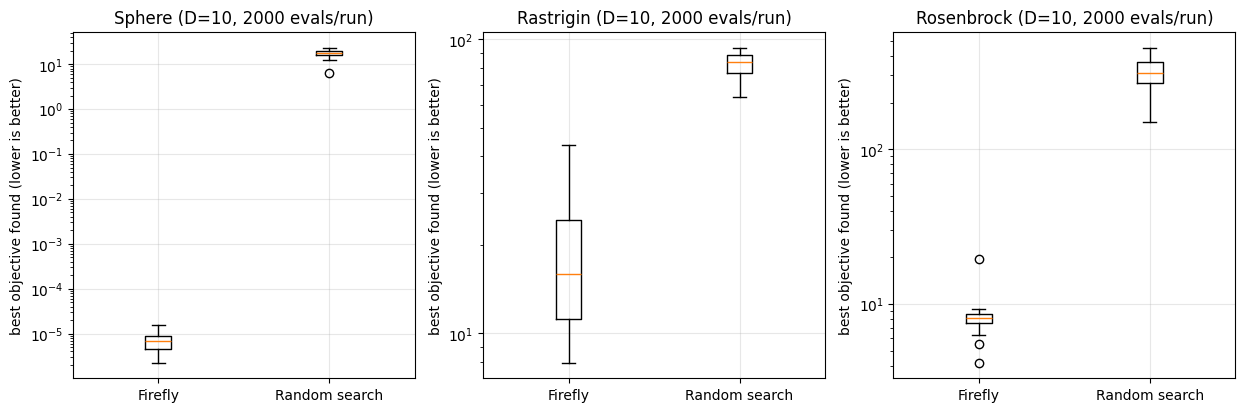

In [4]:
# --- toy benchmarks: FA vs random search with the SAME number of evaluations (30 independent runs each) ---
def sphere(z):     return float(np.sum(z ** 2))
def rastrigin(z):  return float(10 * len(z) + np.sum(z ** 2 - 10 * np.cos(2 * np.pi * z)))
def rosenbrock(z): return float(np.sum(100 * (z[1:] - z[:-1] ** 2) ** 2 + (1 - z[:-1]) ** 2))
BENCH = {"Sphere": (sphere, -5.12, 5.12), "Rastrigin": (rastrigin, -5.12, 5.12), "Rosenbrock": (rosenbrock, -2.048, 2.048)}
D_TOY = 10
budget = CFG["TOY_POP"] * (CFG["TOY_ITERS"] + 1)
toy_rows, toy_vals = [], {}
for name, (fn, lo, hi) in BENCH.items():
    fa_v, rs_v = [], []
    for run in range(CFG["TOY_RUNS"]):
        fit = lambda x, fn=fn, lo=lo, hi=hi: -fn(lo + np.asarray(x) * (hi - lo))
        o = firefly_algorithm(fit, D_TOY, CFG["TOY_POP"], CFG["TOY_ITERS"], CFG["BETA0"], CFG["GAMMA"], CFG["ALPHA0"],
                              CFG["ALPHA_DECAY"], seed=run, verbose=False)
        fa_v.append(-o["best_f"])
        rg = np.random.default_rng(1000 + run)
        rs_v.append(min(fn(lo + rg.random(D_TOY) * (hi - lo)) for _ in range(budget)))
    toy_vals[name] = (np.array(fa_v), np.array(rs_v))
    p = stats.mannwhitneyu(fa_v, rs_v, alternative="less").pvalue
    toy_rows.append(dict(function=name, evaluations_per_run=budget, runs=CFG["TOY_RUNS"], FA_median=np.median(fa_v),
                         RS_median=np.median(rs_v), FA_better_in_runs=int(np.sum(np.array(fa_v) < np.array(rs_v))),
                         mannwhitney_p_FA_smaller=p))
toy = pd.DataFrame(toy_rows); toy.to_csv(f"{OUT}/toy_benchmarks.csv", index=False)
display(toy)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (name, (fa_v, rs_v)) in zip(axs, toy_vals.items()):
    assert_finite("toy " + name, np.concatenate([fa_v, rs_v]))
    ax.boxplot([fa_v, rs_v]); ax.set_xticklabels(["Firefly", "Random search"]); ax.set_yscale("log")
    ax.set_title(f"{name} (D={D_TOY}, {budget} evals/run)"); ax.set_ylabel("best objective found (lower is better)"); ax.grid(alpha=.3)
savefig("00_toy_benchmarks")

## 2. Dataset, problem definition and data splits
**Problem:** classify 28x28 grayscale clothing images into 10 classes. **Dataset:** Fashion-MNIST (60,000 train + 10,000 test).

- `train` (50k) — trains every final model.
- `official validation` (10k) — early stopping of final models and **re-ranking**; never seen by any search.
- `search subset` (20k) and `search validation` (10k) — two **disjoint** parts of `train`, used only inside the search fitness.
- `test` (10k) — locked until the selection is frozen.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Raw shapes: (60000, 28, 28) (60000,) (10000, 28, 28) (10000,)
Missing values: 0 | pixel range: 0 - 255 | label range: 0 - 9
Train (50000, 28, 28, 1) | official Val (10000, 28, 28, 1) | Test (10000, 28, 28, 1) | search subset (20000, 28, 28, 1) | search val (10000, 28, 28, 1)


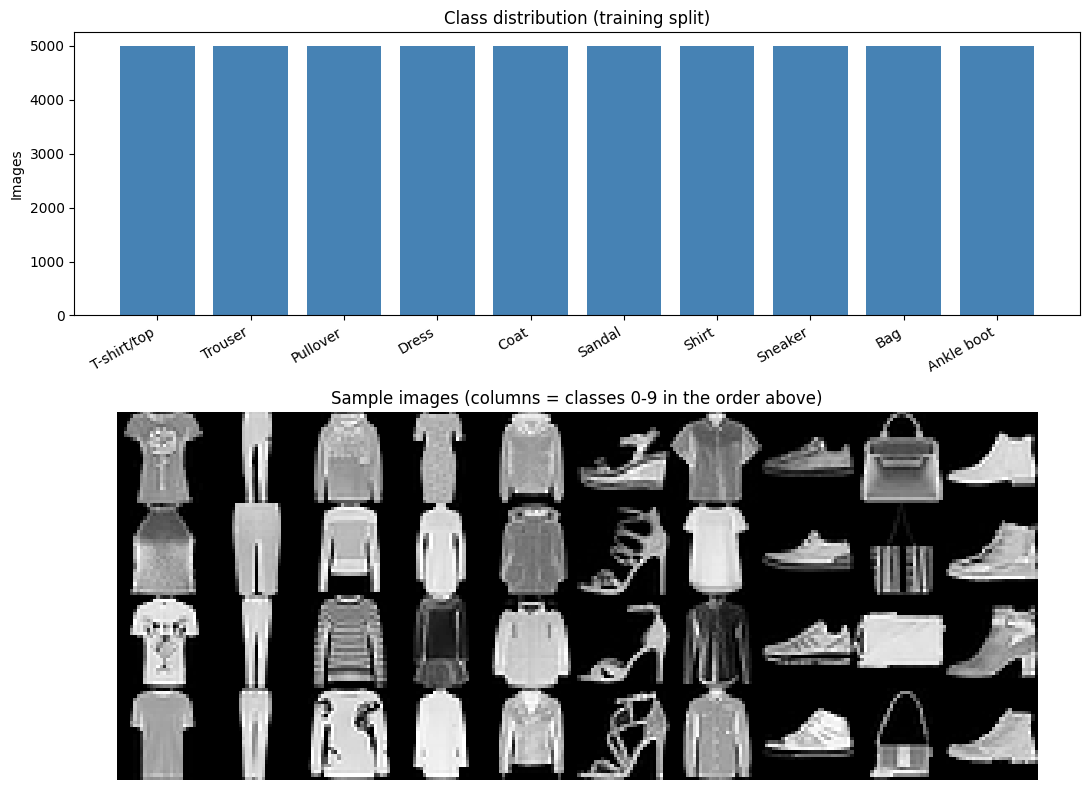

In [5]:
if SMOKE:   # synthetic stand-in, only to test the pipeline
    rs = np.random.RandomState(0)
    X_full = rs.randint(0, 256, (3000, 28, 28)).astype("uint8"); y_full = rs.randint(0, 10, 3000)
    X_test = rs.randint(0, 256, (1000, 28, 28)).astype("uint8");  y_test = rs.randint(0, 10, 1000)
else:
    (X_full, y_full), (X_test, y_test) = keras.datasets.fashion_mnist.load_data()
print("Raw shapes:", X_full.shape, y_full.shape, X_test.shape, y_test.shape)
print("Missing values:", np.isnan(X_full.astype("float32")).sum(), "| pixel range:", X_full.min(), "-", X_full.max(),
      "| label range:", y_full.min(), "-", y_full.max())

X_full = (X_full.astype("float32") / 255.0)[..., None]       # scale to [0,1], add channel axis
X_test = (X_test.astype("float32") / 255.0)[..., None]

idx_all = np.arange(len(X_full))
idx_train, idx_val = train_test_split(idx_all, test_size=CFG["VAL_N"], stratify=y_full, random_state=42)
X_train, y_train = X_full[idx_train], y_full[idx_train]
X_val,   y_val   = X_full[idx_val],   y_full[idx_val]
pos = np.arange(len(X_train))
pos_sub, pos_sval = train_test_split(pos, train_size=CFG["SEARCH_N"], test_size=CFG["SEARCH_VAL_N"],
                                     stratify=y_train, random_state=7)
X_sub,  y_sub  = X_train[pos_sub],  y_train[pos_sub]
X_sval, y_sval = X_train[pos_sval], y_train[pos_sval]
assert not set(pos_sub) & set(pos_sval)
GEN_IDX = np.random.RandomState(0).choice(len(X_train), size=min(10000, len(X_train)), replace=False)
print(f"Train {X_train.shape} | official Val {X_val.shape} | Test {X_test.shape} | search subset {X_sub.shape} | search val {X_sval.shape}")

fig, ax = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={"height_ratios": [1, 1.3]})
counts = np.bincount(y_train, minlength=10); assert_finite("class counts", counts)
ax[0].bar(CLASS_NAMES, counts, color="steelblue"); ax[0].set_title("Class distribution (training split)"); ax[0].set_ylabel("Images")
plt.setp(ax[0].get_xticklabels(), rotation=30, ha="right")
ax[1].axis("off")
grid = np.vstack([np.hstack([X_train[np.where(y_train == c)[0][k], :, :, 0] for c in range(10)]) for k in range(4)])
ax[1].imshow(grid, cmap="gray"); ax[1].set_title("Sample images (columns = classes 0-9 in the order above)")
plt.tight_layout(); savefig("01_dataset_overview")

## 3. CNN, training recipe and the models to compare
`[RandomFlip] -> [RandomTranslation] -> {Conv -> (BatchNorm) -> ReLU -> MaxPool} x (2 or 3) -> Flatten -> Dense -> Dropout -> Dense(10)`; Adam (optional decoupled weight decay).
**Recipe genes:** `flip` (horizontal flip), `shift` (random translation fraction), `cosine` (cosine learning-rate decay over the stage's epoch budget), `wd` (weight decay).
- Constant-LR configurations use early stopping on validation loss (best weights restored); cosine configurations train the full schedule and use the last epoch.
- Augmentation layers are active only during training.

**Strong manual recipe (declared in advance, never tuned):** 3 conv blocks (64/128/128 filters), BatchNorm, dense 256, dropout 0.3, flip + 10% shift, cosine decay, weight decay 0.01, batch 128, lr 1e-3. **V7-selected:** the hyper-parameters chosen by V7's search, frozen.

In [6]:
def make_optimizer(hp, total_steps):
    lr = hp["lr"]
    if hp["cosine"]:
        lr = keras.optimizers.schedules.CosineDecay(lr, decay_steps=max(1, int(total_steps)), alpha=0.02)
    kw = dict(weight_decay=hp["wd"]) if hp["wd"] > 0 else {}
    return keras.optimizers.Adam(lr, **kw)

def build_cnn(hp, total_steps=1000):
    model = keras.Sequential([layers.Input((28, 28, 1))])
    if hp["flip"]:
        model.add(layers.RandomFlip("horizontal"))
    if hp["shift"] > 0:
        model.add(layers.RandomTranslation(hp["shift"], hp["shift"], fill_mode="constant"))
    filters = [hp["f1"], hp["f2"]] + ([hp["f2"]] if hp["n_conv"] == 3 else [])
    for f in filters:
        model.add(layers.Conv2D(f, 3, padding="same"))
        if hp["bn"]:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        model.add(layers.MaxPooling2D())
    model.add(layers.Flatten())
    model.add(layers.Dense(hp["dense"], activation="relu"))
    model.add(layers.Dropout(hp["dropout"]))
    model.add(layers.Dense(10, activation="softmax"))
    model.compile(optimizer=make_optimizer(hp, total_steps), loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"], jit_compile=False)
    return model

BASE_HP = dict(lr=1e-3, f1=32, f2=64, dense=128, dropout=0.25, batch=128, n_conv=2, bn=0, flip=0, shift=0.0, cosine=0, wd=0.0)
MANUAL_HP = dict(lr=1e-3, f1=64, f2=128, dense=256, dropout=0.3, batch=128, n_conv=3, bn=1, flip=1, shift=0.1, cosine=1, wd=0.01)
V7_HP = dict(lr=0.0009309036507861036, f1=25, f2=58, dense=132, dropout=0.362, batch=128, n_conv=2, bn=0,
             flip=0, shift=0.0, cosine=0, wd=0.0)          # selected by the V7 search (frozen)
BASE_PARAMS = build_cnn(BASE_HP).count_params()
print("Baseline parameters:", BASE_PARAMS, "| manual recipe parameters:", build_cnn(MANUAL_HP).count_params())

def parsimony(params):
    return max(0.0, float(np.log2(params / BASE_PARAMS)))

def fit_model(hp, X, y, Xv, yv, max_epochs, patience, seed):
    set_seed(seed)
    total_steps = int(np.ceil(len(X) / hp["batch"])) * max_epochs
    model = build_cnn(hp, total_steps)
    cbs = [] if hp["cosine"] else [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    h = model.fit(X, y, validation_data=(Xv, yv), epochs=max_epochs, batch_size=hp["batch"], callbacks=cbs, verbose=0)
    return model, h.history

def final_val_loss(hist, hp):
    return float(hist["val_loss"][-1] if hp["cosine"] else min(hist["val_loss"]))

def evaluate_on_test(model):
    assert not TEST["locked"], "Test set is locked until the selection is frozen"
    if TEST["first_eval_ts"] is None:
        TEST["first_eval_ts"] = time.time()
    prob = model.predict(X_test, verbose=0).astype("float64")
    prob /= prob.sum(1, keepdims=True)
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    return dict(accuracy=float((pred == y_test).mean()), precision=p, recall=r, f1=f,
                auc=roc_auc_score(y_test, prob, multi_class="ovr", average="macro"),
                test_loss=log_loss(y_test, prob, labels=list(range(10)))), pred

def evaluate_generalization(model):
    tr_loss, tr_acc = model.evaluate(X_train[GEN_IDX], y_train[GEN_IDX], verbose=0)
    va_loss, va_acc = model.evaluate(X_val, y_val, verbose=0)
    return dict(train_acc=tr_acc, train_loss=tr_loss, val_acc=va_acc, val_loss_final=va_loss)

I0000 00:00:1793272157.080047      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793272157.083361      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Baseline parameters: 421642 | manual recipe parameters: 521098


## 4. The search: 12 hyper-parameters, matched replicates of FA and random search
Brightness = `-(validation loss on the SEARCH validation set + LAMBDA * parsimony)`, measured after a convergence-based proxy run (20k images, up to 12 epochs). Each replicate has its own FA seed, random-search seed and **fitness training seed**; random search uses the same objective, data, search space and number of **distinct** configurations as FA. The baseline is seeded into both populations (the manual recipe is *not*).

In [7]:
LOW  = np.array([-4.0, 16,  32,  64, 0.1, 0, 2, 0, 0, 0.00, 0, 0.00])
HIGH = np.array([-2.0, 64, 128, 256, 0.5, 2, 3, 1, 1, 0.12, 1, 0.05])
BATCHES = [32, 64, 128]
DIM = len(LOW)

def decode(x):
    v = LOW + np.clip(x, 0, 1) * (HIGH - LOW)
    return dict(lr=float(10 ** v[0]), f1=int(round(v[1])), f2=int(round(v[2])), dense=int(round(v[3])),
                dropout=float(round(v[4], 3)), batch=BATCHES[int(round(v[5]))], n_conv=int(round(v[6])),
                bn=int(round(v[7])), flip=int(round(v[8])), shift=float(round(v[9], 3)),
                cosine=int(round(v[10])), wd=float(round(v[11], 4)))

def encode(hp):
    v = np.array([np.log10(hp["lr"]), hp["f1"], hp["f2"], hp["dense"], hp["dropout"], BATCHES.index(hp["batch"]),
                  hp["n_conv"], hp["bn"], hp["flip"], hp["shift"], hp["cosine"], hp["wd"]], dtype=float)
    return (v - LOW) / (HIGH - LOW)

def hp_key(x):
    return tuple(decode(x).values())

assert decode(encode(BASE_HP)) == BASE_HP and decode(encode(MANUAL_HP)) == MANUAL_HP
BASE_KEY = tuple(BASE_HP.values())

CACHE_FILE = f"{OUT}/fitness_cache.json"
CACHE_SIG = json.dumps({"version": CODE_VERSION, "smoke": SMOKE, "baseline": BASE_HP,
                        "search": {k: CFG[k] for k in ["SEARCH_N", "SEARCH_VAL_N", "SEARCH_EPOCHS", "SEARCH_PATIENCE", "LAMBDA", "VAL_N"]},
                        "LOW": LOW.tolist(), "HIGH": HIGH.tolist(), "BATCHES": BATCHES}, sort_keys=True)
_cache = {}      # (fitness seed, decoded config...) -> [objective, raw search-val loss, parameters, epochs trained]
if os.path.exists(CACHE_FILE):
    saved = json.load(open(CACHE_FILE))
    if saved.get("sig") == CACHE_SIG:
        _cache = {tuple(k): v for k, v in saved["items"]}
        print("Resumed", len(_cache), "cached search evaluations")
def save_cache():
    json.dump(dict(sig=CACHE_SIG, items=[[list(k), v] for k, v in _cache.items()]), open(CACHE_FILE, "w"))

def make_fitness(fit_seed):
    def fitness(x):
        hp = decode(x); key = (fit_seed,) + tuple(hp.values())
        if key in _cache:
            return _cache[key][0]
        model, hist = fit_model(hp, X_sub, y_sub, X_sval, y_sval, CFG["SEARCH_EPOCHS"], CFG["SEARCH_PATIENCE"], fit_seed)
        params = model.count_params()
        val_loss = float(model.evaluate(X_sval, y_sval, verbose=0)[0])
        keras.backend.clear_session()
        _cache[key] = [-(val_loss + CFG["LAMBDA"] * parsimony(params)), val_loss, int(params), len(hist["loss"])]
        save_cache()
        return _cache[key][0]
    return fitness

R = min(CFG["REPEATS"], len(CFG["FA_SEEDS"]), len(CFG["RS_SEEDS"]), len(CFG["FIT_SEEDS"]))
fit_fns = [make_fitness(sd) for sd in CFG["FIT_SEEDS"][:R]]
base_fits = [f(encode(BASE_HP)) for f in fit_fns]
print(f"Replicates: {R} | baseline search objective per replicate: {[round(-b, 4) for b in base_fits]}")

Replicates: 2 | baseline search objective per replicate: [0.2627, 0.2687]


In [8]:
reps = []
for r in range(R):
    print(f"\n===== Replicate {r + 1}/{R}: FA seed {CFG['FA_SEEDS'][r]}, RS seed {CFG['RS_SEEDS'][r]}, fitness training seed {CFG['FIT_SEEDS'][r]} =====")
    t0 = time.time()
    fa_r = firefly_algorithm(fit_fns[r], DIM, CFG["FA_POP"], CFG["FA_ITERS"], CFG["BETA0"], CFG["GAMMA"],
                             CFG["ALPHA0"], CFG["ALPHA_DECAY"], seed=CFG["FA_SEEDS"][r], init=[encode(BASE_HP)])
    fa_min = (time.time() - t0) / 60
    keys_r = {hp_key(e["x"]) for e in fa_r["eval_log"]}; keys_r.add(BASE_KEY)
    n_r = max(2, len(keys_r))
    rng = np.random.default_rng(CFG["RS_SEEDS"][r])
    Xr, seen_r = [encode(BASE_HP)], {BASE_KEY}
    while len(Xr) < n_r:                                    # distinct decoded configs only
        c = rng.random(DIM)
        if hp_key(c) not in seen_r:
            Xr.append(c); seen_r.add(hp_key(c))
    Xr = np.asarray(Xr)
    t0 = time.time()
    fr = np.array([fit_fns[r](x) for x in Xr])
    rs_min = (time.time() - t0) / 60
    fa_work = sum(_cache[(CFG["FIT_SEEDS"][r],) + k][3] for k in keys_r)
    rs_work = sum(_cache[(CFG["FIT_SEEDS"][r],) + hp_key(x)][3] for x in Xr)
    reps.append(dict(r=r, fit_seed=CFG["FIT_SEEDS"][r], fa=fa_r, fit_fn=fit_fns[r], base_fit=base_fits[r], X_rand=Xr, f_rand=fr,
                     fa_minutes=fa_min, rs_minutes=rs_min, n_fa=len(keys_r), n_rs=len(seen_r), fa_epochs=fa_work, rs_epochs=rs_work))
    print(f"Replicate {r + 1}: distinct configs FA {len(keys_r)} vs RS {len(seen_r)} | proxy epochs trained FA {fa_work} vs RS {rs_work} | "
          f"best objective baseline {-base_fits[r]:.4f} | RS {-fr.max():.4f} | FA {-fa_r['best_f']:.4f}")
fa = reps[0]["fa"]
fa_minutes = sum(rp["fa_minutes"] for rp in reps); rs_minutes = sum(rp["rs_minutes"] for rp in reps)


===== Replicate 1/2: FA seed 1, RS seed 123, fitness training seed 42 =====
iter  0 | best objective 0.2627 | mean 0.3554
iter  1 | best objective 0.2446 | mean 0.2699 | alpha 0.279
iter  2 | best objective 0.2446 | mean 0.2575 | alpha 0.259
iter  3 | best objective 0.2417 | mean 0.2485 | alpha 0.241
iter  4 | best objective 0.2337 | mean 0.2432 | alpha 0.224
iter  5 | best objective 0.2337 | mean 0.2431 | alpha 0.209
iter  6 | best objective 0.2332 | mean 0.2393 | alpha 0.194
Replicate 1: distinct configs FA 56 vs RS 56 | proxy epochs trained FA 658 vs RS 657 | best objective baseline 0.2627 | RS 0.2340 | FA 0.2332

===== Replicate 2/2: FA seed 2, RS seed 124, fitness training seed 43 =====
iter  0 | best objective 0.2210 | mean 0.3110
iter  1 | best objective 0.2210 | mean 0.2408 | alpha 0.279
iter  2 | best objective 0.2210 | mean 0.2331 | alpha 0.259
iter  3 | best objective 0.2210 | mean 0.2275 | alpha 0.241
iter  4 | best objective 0.2204 | mean 0.2230 | alpha 0.224
iter  5 | be

### 4.1 Independent re-ranking of finalists, then the frozen selection
The top finalists of each method (per replicate, distinct, baseline excluded) are fully trained on the selection seeds and ranked on the **official validation set**. The baseline, the manual recipe and the V7-selected configuration are scored the same way **for context only**. Winners are chosen by the rule `mean val loss + LAMBDA * parsimony`, before the test set is touched.

In [9]:
def row_to_hp(row):
    return {c: (float(row[c]) if c in ("lr", "dropout", "shift", "wd") else int(row[c])) for c in HP_COLS}

def table_from(xs, fs, fit_seed, extra=None):
    rows = []
    for i, (x, f) in enumerate(zip(xs, fs)):
        info = _cache[(fit_seed,) + hp_key(x)]
        rows.append(dict(evaluation_index=i, objective=-f, search_val_loss=info[1], params=info[2], epochs=info[3],
                         **decode(x), **(extra[i] if extra else {})))
    return pd.DataFrame(rows)

fa_tabs, rs_tabs, pop_rows = [], [], []
for rp in reps:
    ev = rp["fa"]["eval_log"]
    t_ = table_from([e["x"] for e in ev], [e["fitness"] for e in ev], rp["fit_seed"],
                    extra=[dict(iteration=e["iteration"], firefly=e["firefly"]) for e in ev])
    seen_k, flags = set(), []
    for _, r_ in t_.iterrows():
        k_ = tuple(r_[c] for c in HP_COLS); flags.append(k_ not in seen_k); seen_k.add(k_)
    t_["new_config"] = flags; t_["replicate"] = rp["r"] + 1; fa_tabs.append(t_)
    s_ = table_from(rp["X_rand"], rp["f_rand"], rp["fit_seed"]); s_["replicate"] = rp["r"] + 1; rs_tabs.append(s_)
    for it, (P, F) in enumerate(zip(rp["fa"]["pos_hist"], rp["fa"]["fit_hist"])):
        for k in range(len(P)):
            pop_rows.append(dict(replicate=rp["r"] + 1, iteration=it, firefly=k, brightness=F[k], **decode(P[k])))
fa_all = pd.concat(fa_tabs, ignore_index=True); rs_all = pd.concat(rs_tabs, ignore_index=True)
fa_all.to_csv(f"{OUT}/fa_evaluations.csv", index=False); rs_all.to_csv(f"{OUT}/random_search_evaluations.csv", index=False)
pd.DataFrame(pop_rows).to_csv(f"{OUT}/firefly_log.csv", index=False)

def finalists(tabs, k):
    pool = {}
    for t_ in tabs:
        taken = 0
        for _, row in t_.sort_values("objective").drop_duplicates(subset=HP_COLS).iterrows():
            hp = row_to_hp(row)
            if hp == BASE_HP:
                continue
            d_ = pool.setdefault(tuple(hp[c] for c in HP_COLS), dict(hp=hp, reps=[], obj=[], raw=[]))
            d_["reps"].append(int(row["replicate"])); d_["obj"].append(float(row["objective"])); d_["raw"].append(float(row["search_val_loss"]))
            taken += 1
            if taken == k:
                break
    return [(float(np.mean(v["obj"])), float(np.mean(v["raw"])), v["hp"], v["reps"]) for v in pool.values()]
fa_final = finalists(fa_tabs, CFG["TOP_K_PER_REP"]); rs_final = finalists(rs_tabs, CFG["TOP_K_PER_REP"])

def proxy_of(hp):
    # proxy (search) loss of any configuration: mean over the replicates' fitness training seeds
    vals = []
    for rp in reps:
        rp["fit_fn"](encode(hp)); vals.append(_cache[(rp["fit_seed"],) + tuple(hp.values())][1:3])
    return float(np.mean([v[0] for v in vals])), int(vals[0][1])

def select_score(hp):
    rs_ = []
    for sd in CFG["SELECT_SEEDS"]:
        def once(hp=hp, sd=sd):
            model, hist = fit_model(hp, X_train, y_train, X_val, y_val, CFG["FINAL_EPOCHS"], CFG["FINAL_PATIENCE"], sd)
            out = dict(val_loss=final_val_loss(hist, hp), epochs=len(hist["loss"]), params=int(model.count_params()))
            keras.backend.clear_session(); return out
        rs_.append(memo("select", dict(hp=hp, seed=sd, ep=CFG["FINAL_EPOCHS"], pat=CFG["FINAL_PATIENCE"]), once))
    m = float(np.mean([r_["val_loss"] for r_ in rs_])); params = rs_[0]["params"]
    return dict(full_val_loss=m, full_val_std=float(np.std([r_["val_loss"] for r_ in rs_])),
                mean_epochs=float(np.mean([r_["epochs"] for r_ in rs_])), params=params, objective=m + CFG["LAMBDA"] * parsimony(params))

t_rr = time.time()
entries = [("context: Default CNN", dict(BASE_HP)), ("context: Strong manual recipe", dict(MANUAL_HP)), ("context: V7-selected", dict(V7_HP))]
entries += [("FA finalist", c[2]) for c in fa_final] + [("RS finalist", c[2]) for c in rs_final]
rerank_rows = []
for role, hp in entries:
    sc = select_score(hp)
    px, _ = proxy_of(hp)
    rerank_rows.append(dict(role=role, proxy_val_loss=px, **sc, **hp))
    print(f"{role:32s} proxy {px:.4f} | full val loss {sc['full_val_loss']:.4f} +/- {sc['full_val_std']:.4f} | params {sc['params']} | objective {sc['objective']:.4f} | {hp}")
rerank = pd.DataFrame(rerank_rows); rerank.to_csv(f"{OUT}/rerank_candidates.csv", index=False)
rerank_minutes = (time.time() - t_rr) / 60

fa_rows = rerank[rerank.role == "FA finalist"]; rs_rows = rerank[rerank.role == "RS finalist"]
assert len(fa_rows) > 0 and len(rs_rows) > 0, "no finalists"
FA_BEST_HP = row_to_hp(fa_rows.loc[fa_rows.objective.idxmin()]); RS_BEST_HP = row_to_hp(rs_rows.loc[rs_rows.objective.idxmin()])
base_row = rerank[rerank.role == "context: Default CNN"].iloc[0]
print("\nFA-selected :", FA_BEST_HP); print("RS-selected :", RS_BEST_HP)
print(f"Independent validation objective | FA best {fa_rows.objective.min():.4f} | RS best {rs_rows.objective.min():.4f} | default {base_row.objective:.4f}")

MODELS = {"Default CNN": BASE_HP, "V7-selected (frozen)": V7_HP, "Strong manual recipe": MANUAL_HP,
          "FA-selected (V8)": FA_BEST_HP, "RS-selected (V8)": RS_BEST_HP}
frozen = dict(created_utc=time.strftime("%Y-%m-%d %H:%M:%S", time.gmtime()), created_ts=time.time(), models=MODELS,
              selection_rule="min mean validation loss + LAMBDA*parsimony on the official validation set, finalists only",
              config=CFG)
json.dump(frozen, open(f"{OUT}/frozen_selection.json", "w"), indent=2)
TEST["locked"] = False          # selection frozen: the test set may now be used, once, by the final stage
print("Selection frozen and written to frozen_selection.json; test set unlocked.")

context: Default CNN             proxy 0.2657 | full val loss 0.2107 +/- 0.0035 | params 421642 | objective 0.2107 | {'lr': 0.001, 'f1': 32, 'f2': 64, 'dense': 128, 'dropout': 0.25, 'batch': 128, 'n_conv': 2, 'bn': 0, 'flip': 0, 'shift': 0.0, 'cosine': 0, 'wd': 0.0}
context: Strong manual recipe    proxy 0.2644 | full val loss 0.1763 +/- 0.0016 | params 521098 | objective 0.1855 | {'lr': 0.001, 'f1': 64, 'f2': 128, 'dense': 256, 'dropout': 0.3, 'batch': 128, 'n_conv': 3, 'bn': 1, 'flip': 1, 'shift': 0.1, 'cosine': 1, 'wd': 0.01}
context: V7-selected             proxy 0.2599 | full val loss 0.2092 +/- 0.0054 | params 389964 | objective 0.2092 | {'lr': 0.0009309036507861036, 'f1': 25, 'f2': 58, 'dense': 132, 'dropout': 0.362, 'batch': 128, 'n_conv': 2, 'bn': 0, 'flip': 0, 'shift': 0.0, 'cosine': 0, 'wd': 0.0}
FA finalist                      proxy 0.2339 | full val loss 0.1955 +/- 0.0057 | params 256524 | objective 0.1955 | {'lr': 0.002289609202294331, 'f1': 37, 'f2': 111, 'dense': 107, 

### 4.2 Diagnostics: proxy fidelity, noise, interactions (use validation data only)

In [10]:
# ---------- proxy fidelity: does the cheap search loss rank configurations like full training? ----------
fid = rerank[["role", "proxy_val_loss", "full_val_loss", "params"]].copy(); fid.to_csv(f"{OUT}/proxy_fidelity.csv", index=False)
def spearman_ci(x, y, n=5000, seed=0):
    rho = stats.spearmanr(x, y)[0]; rg = np.random.default_rng(seed); n_ = len(x); b = []
    for _ in range(n):
        i = rg.integers(0, n_, n_)
        if len(set(np.asarray(x)[i])) > 1 and len(set(np.asarray(y)[i])) > 1:
            b.append(stats.spearmanr(np.asarray(x)[i], np.asarray(y)[i])[0])
    return float(rho), (float(np.quantile(b, .025)), float(np.quantile(b, .975))) if b else (float("nan"), float("nan"))
rho, rho_ci = spearman_ci(fid.proxy_val_loss.to_numpy(), fid.full_val_loss.to_numpy()) if len(fid) >= 4 else (float("nan"), (float("nan"),) * 2)
print(f"Spearman rho (proxy vs full-training validation loss) = {rho:.3f}, bootstrap 95% CI [{rho_ci[0]:.3f}, {rho_ci[1]:.3f}], n = {len(fid)}")

# ---------- proxy seed noise and selection optimism ----------
def proxy_detail(hp, seed):
    def once():
        model, hist = fit_model(hp, X_sub, y_sub, X_sval, y_sval, CFG["SEARCH_EPOCHS"], CFG["SEARCH_PATIENCE"], seed)
        out = (float(model.evaluate(X_sval, y_sval, verbose=0)[0]), float(model.evaluate(X_val, y_val, verbose=0)[0]))
        keras.backend.clear_session(); return out
    return memo("noise", dict(hp=hp, seed=seed, n=CFG["SEARCH_N"], ep=CFG["SEARCH_EPOCHS"]), once)
noise_rows = []
for name, hp in (("default", BASE_HP), ("FA-selected", FA_BEST_HP)):
    for s in CFG["NOISE_SEEDS"]:
        sv, ov = proxy_detail(hp, s); noise_rows.append(dict(config=name, seed=s, search_val_loss=sv, independent_val_loss=ov))
noise = pd.DataFrame(noise_rows); noise.to_csv(f"{OUT}/proxy_noise_study.csv", index=False)
g = noise.groupby("config").agg(sv_mean=("search_val_loss", "mean"), sv_std=("search_val_loss", "std"),
                                ov_mean=("independent_val_loss", "mean"), ov_std=("independent_val_loss", "std"))
g["optimism_ov_minus_sv"] = g.ov_mean - g.sv_mean
display(g.round(4))
noise_sd = float(np.sqrt((g.sv_std ** 2).mean()))
gap_proxy = float(g.loc["default", "sv_mean"] - g.loc["FA-selected", "sv_mean"])
print(f"Proxy advantage of FA-selected over default: {gap_proxy:+.4f} | proxy seed-noise SD ~ {noise_sd:.4f}")

# ---------- interactions: cross-validated R^2 of the search landscape ----------
allcfg = (pd.concat([fa_all[fa_all.new_config][HP_COLS + ["search_val_loss"]], rs_all[HP_COLS + ["search_val_loss"]]])
          .groupby(HP_COLS, as_index=False)["search_val_loss"].mean())
Xf = allcfg[HP_COLS].copy(); Xf["lr"] = np.log10(Xf["lr"]); yv = np.clip(allcfg.search_val_loss.to_numpy(), None, 1.0)
r2 = dict(linear=np.nan, with_interactions=np.nan, quadratic=np.nan)
if len(allcfg) >= 15:
    cv = KFold(n_splits=5, shuffle=True, random_state=0)
    for key, deg, io in (("linear", 1, False), ("with_interactions", 2, True), ("quadratic", 2, False)):
        steps = [StandardScaler()] + ([PolynomialFeatures(degree=deg, interaction_only=io, include_bias=False), StandardScaler()] if deg > 1 else [])
        r2[key] = float(cross_val_score(make_pipeline(*steps, Ridge(alpha=3.0)), Xf.to_numpy(), yv, cv=cv, scoring="r2").mean())
lin = make_pipeline(StandardScaler(), Ridge(alpha=3.0)).fit(Xf.to_numpy(), yv)
coef = pd.Series(lin[-1].coef_, index=HP_COLS).sort_values(key=np.abs, ascending=False)
print(f"configs analysed: {len(allcfg)} | CV R^2 -> linear {r2['linear']:.3f} | + interactions {r2['with_interactions']:.3f} | quadratic {r2['quadratic']:.3f}")
print("Largest standardized linear effects on search loss:"); print(coef.head(5).round(4).to_string())

Spearman rho (proxy vs full-training validation loss) = 0.209, bootstrap 95% CI [-0.537, 0.793], n = 11


,sv_mean,sv_std,ov_mean,ov_std,optimism_ov_minus_sv
config,,,,,
FA-selected,0.217,0.0036,0.2145,0.0082,-0.0025
default,0.267,0.0115,0.2591,0.0061,-0.0080


Proxy advantage of FA-selected over default: +0.0500 | proxy seed-noise SD ~ 0.0085
configs analysed: 221 | CV R^2 -> linear 0.473 | + interactions 0.381 | quadratic 0.772
Largest standardized linear effects on search loss:
lr       -0.0206
shift     0.0175
bn       -0.0134
batch     0.0098
cosine   -0.0080


## 5. Final comparison (test set used once, after the frozen selection)

In [11]:
def run_final(hp, name):
    rows, hists, preds = [], [], []
    for s in CFG["SEEDS"]:
        def once(hp=hp, s=s):
            t0 = time.time()
            model, hist = fit_model(hp, X_train, y_train, X_val, y_val, CFG["FINAL_EPOCHS"], CFG["FINAL_PATIENCE"], s)
            secs = time.time() - t0
            m, pred = evaluate_on_test(model)
            m.update(evaluate_generalization(model))
            m.update(seed=s, train_seconds=secs, params=int(model.count_params()), epochs_used=len(hist["loss"]))
            m["gap_train_test"] = m["train_acc"] - m["accuracy"]; m["gap_val_test"] = m["val_acc"] - m["accuracy"]
            keras.backend.clear_session()
            return dict(m=m, hist={k: [float(v) for v in vals] for k, vals in hist.items()}, pred=pred)
        res = memo("final", dict(hp=hp, seed=s, ep=CFG["FINAL_EPOCHS"], pat=CFG["FINAL_PATIENCE"]), once)
        rows.append(res["m"]); hists.append(res["hist"]); preds.append(res["pred"])
        print(f"[{name}] seed {s}: test acc {res['m']['accuracy']:.4f} | {res['m']['epochs_used']} epochs | {res['m']['train_seconds']:.0f}s")
    return dict(name=name, hp=hp, metrics=pd.DataFrame(rows), hists=hists, preds=preds)

finals = {name: run_final(hp, name) for name, hp in MODELS.items()}
names = list(finals)

[Default CNN] seed 0: test acc 0.9221 | 17 epochs | 41s
[Default CNN] seed 1: test acc 0.9156 | 16 epochs | 39s
[Default CNN] seed 2: test acc 0.9140 | 15 epochs | 36s
[Default CNN] seed 3: test acc 0.9130 | 14 epochs | 35s
[Default CNN] seed 4: test acc 0.9185 | 14 epochs | 34s
[Default CNN] seed 5: test acc 0.9121 | 12 epochs | 31s
[Default CNN] seed 6: test acc 0.9132 | 13 epochs | 32s
[Default CNN] seed 7: test acc 0.9190 | 15 epochs | 37s
[Default CNN] seed 8: test acc 0.9152 | 14 epochs | 34s
[Default CNN] seed 9: test acc 0.9177 | 14 epochs | 34s
[Default CNN] seed 10: test acc 0.9150 | 12 epochs | 30s
[Default CNN] seed 11: test acc 0.9155 | 15 epochs | 37s
[V7-selected (frozen)] seed 0: test acc 0.9145 | 20 epochs | 48s
[V7-selected (frozen)] seed 1: test acc 0.9163 | 18 epochs | 43s
[V7-selected (frozen)] seed 2: test acc 0.9171 | 18 epochs | 43s
[V7-selected (frozen)] seed 3: test acc 0.9155 | 17 epochs | 41s
[V7-selected (frozen)] seed 4: test acc 0.9192 | 17 epochs | 41s
[

### 5.1 Metrics, statistics (Holm-corrected, equivalence test) and generalization

In [12]:
display(pd.DataFrame(MODELS))
metric_cols = ["accuracy", "precision", "recall", "f1", "auc"]
rows = []
for n in names:
    m = finals[n]["metrics"]
    rows.append({"Model": n, **{(c.capitalize() if c != "auc" else "AUC"): f"{m[c].mean():.4f} +/- {m[c].std():.4f}" for c in metric_cols},
                 "Test loss": f"{m.test_loss.mean():.4f} +/- {m.test_loss.std():.4f}", "Params": int(m.params.iloc[0]),
                 "Epochs": f"{m.epochs_used.mean():.1f}", "Train time (s)": f"{m.train_seconds.mean():.0f}"})
summary = pd.DataFrame(rows).set_index("Model"); display(summary); summary.to_csv(f"{OUT}/summary_metrics.csv")
pd.concat([finals[n]["metrics"].assign(model=n) for n in names]).to_csv(f"{OUT}/per_seed_metrics.csv", index=False)

def tost_p(d, margin):
    if len(d) < 2 or np.std(d, ddof=1) == 0: return np.nan
    return float(max(stats.ttest_1samp(d, -margin, alternative="greater").pvalue, stats.ttest_1samp(d, margin, alternative="less").pvalue))

def paired(a, b, label):
    d = (np.asarray(a) - np.asarray(b)) * 100.0                      # percentage points
    sd = d.std(ddof=1) if len(d) > 1 else 0.0
    t_p = stats.ttest_rel(a, b).pvalue if sd > 0 else np.nan
    try: w_p = stats.wilcoxon(a, b).pvalue
    except Exception: w_p = np.nan
    rg = np.random.default_rng(2026)
    boot = np.array([rg.choice(d, size=len(d), replace=True).mean() for _ in range(10000)])
    lo, hi = np.quantile(boot, [0.025, 0.975])
    return dict(comparison=label, mean_diff_pp=d.mean(), ci95_low_pp=lo, ci95_high_pp=hi, t_test_p=t_p, wilcoxon_p=w_p,
                cohens_dz=(d.mean() / sd if sd > 0 else np.nan), tost_p=tost_p(d, CFG["EQUIV_MARGIN_PP"]), n_seeds=len(d))

def holm(ps):
    ps = np.asarray(ps, dtype=float); order = np.argsort(np.where(np.isnan(ps), np.inf, ps)); adj = np.full(len(ps), np.nan); run = 0.0
    m = int(np.sum(~np.isnan(ps)))
    for rank, i in enumerate(order[:m]):
        run = max(run, (m - rank) * ps[i]); adj[i] = min(1.0, run)
    return adj

acc = {n: finals[n]["metrics"].accuracy.to_numpy() for n in names}
pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1:]]
pw = pd.DataFrame([paired(acc[a], acc[b], f"{a} - {b}") for a, b in pairs])
pw["holm_p_all_pairs"] = holm(pw.t_test_p.to_numpy())
PRIMARY = [("FA-selected (V8)", "Default CNN"), ("FA-selected (V8)", "Strong manual recipe"), ("FA-selected (V8)", "RS-selected (V8)")]
pw["primary"] = pw.comparison.isin([f"{a} - {b}" for a, b in PRIMARY]) | pw.comparison.isin([f"{b} - {a}" for a, b in PRIMARY])
prim_idx = pw.index[pw.primary].tolist(); pw["holm_p_primary"] = np.nan
pw.loc[prim_idx, "holm_p_primary"] = holm(pw.loc[prim_idx, "t_test_p"].to_numpy())
pw.to_csv(f"{OUT}/pairwise_tests.csv", index=False); display(pw.round(4))

gcols = ["train_acc", "val_acc", "accuracy", "gap_train_test", "gap_val_test", "train_loss", "val_loss_final", "test_loss"]
gen = pd.DataFrame({n: {c: f"{finals[n]['metrics'][c].mean():.4f} +/- {finals[n]['metrics'][c].std():.4f}" for c in gcols} for n in names}).T
gen.columns = ["Train acc", "Val acc", "Test acc", "Gap train-test", "Gap val-test", "Train loss", "Val loss", "Test loss"]
display(gen); gen.to_csv(f"{OUT}/generalization_diagnostics.csv")

,Default CNN,V7-selected (frozen),Strong manual recipe,FA-selected (V8),RS-selected (V8)
lr,0.001,0.000931,0.001,0.002239,0.000482
f1,32.000,25.000000,64.000,42.000000,35.000000
f2,64.000,58.000000,128.000,100.000000,118.000000
dense,128.000,132.000000,256.000,203.000000,251.000000
dropout,0.250,0.362000,0.300,0.500000,0.304000
batch,128.000,128.000000,128.000,32.000000,64.000000
n_conv,2.000,2.000000,3.000,3.000000,3.000000
bn,0.000,0.000000,1.000,1.000000,1.000000
flip,0.000,0.000000,1.000,0.000000,0.000000
shift,0.000,0.000000,0.100,0.040000,0.067000


,Accuracy,Precision,Recall,F1,AUC,Test loss,Params,Epochs,Train time (s)
Model,,,,,,,,,
Default CNN,0.9159 +/- 0.0029,0.9161 +/- 0.0030,0.9159 +/- 0.0029,0.9157 +/- 0.0030,0.9948 +/- 0.0003,0.2386 +/- 0.0063,421642,14.2,35
V7-selected (frozen),0.9163 +/- 0.0016,0.9167 +/- 0.0015,0.9163 +/- 0.0016,0.9161 +/- 0.0015,0.9950 +/- 0.0002,0.2369 +/- 0.0050,389964,17.2,42
Strong manual recipe,0.9305 +/- 0.0019,0.9306 +/- 0.0018,0.9305 +/- 0.0019,0.9305 +/- 0.0019,0.9962 +/- 0.0001,0.1967 +/- 0.0038,521098,30.0,239
FA-selected (V8),0.9353 +/- 0.0012,0.9356 +/- 0.0012,0.9353 +/- 0.0012,0.9353 +/- 0.0012,0.9967 +/- 0.0001,0.1935 +/- 0.0026,314331,30.0,480
RS-selected (V8),0.9336 +/- 0.0012,0.9338 +/- 0.0012,0.9336 +/- 0.0012,0.9336 +/- 0.0012,0.9966 +/- 0.0001,0.1908 +/- 0.0025,433489,30.0,282


,comparison,mean_diff_pp,ci95_low_pp,ci95_high_pp,t_test_p,wilcoxon_p,cohens_dz,tost_p,n_seeds,holm_p_all_pairs,primary,holm_p_primary
0,Default CNN - V7-selected (frozen),-0.0425,-0.1942,0.1467,0.6452,0.2925,-0.1366,0.0002,12,0.6452,False,NaN
1,Default CNN - Strong manual recipe,-1.4617,-1.6725,-1.2283,0.0000,0.0005,-3.5860,1.0000,12,0.0000,False,NaN
2,Default CNN - FA-selected (V8),-1.9375,-2.0917,-1.7708,0.0000,0.0005,-6.6299,1.0000,12,0.0000,True,0.0000
3,Default CNN - RS-selected (V8),-1.7675,-1.9475,-1.5792,0.0000,0.0005,-5.2891,1.0000,12,0.0000,False,NaN
4,V7-selected (frozen) - Strong manual recipe,-1.4192,-1.5183,-1.3075,0.0000,0.0005,-7.2794,1.0000,12,0.0000,False,NaN
5,V7-selected (frozen) - FA-selected (V8),-1.8950,-1.9767,-1.8158,0.0000,0.0005,-12.6899,1.0000,12,0.0000,False,NaN
6,V7-selected (frozen) - RS-selected (V8),-1.7250,-1.8233,-1.6200,0.0000,0.0005,-9.0653,1.0000,12,0.0000,False,NaN
7,Strong manual recipe - FA-selected (V8),-0.4758,-0.5867,-0.3567,0.0000,0.0005,-2.2534,0.3497,12,0.0000,True,0.0000
8,Strong manual recipe - RS-selected (V8),-0.3058,-0.4000,-0.2183,0.0001,0.0005,-1.7906,0.0012,12,0.0002,False,NaN
9,FA-selected (V8) - RS-selected (V8),0.1700,0.0883,0.2500,0.0027,0.0078,1.1135,0.0000,12,0.0053,True,0.0027


,Train acc,Val acc,Test acc,Gap train-test,Gap val-test,Train loss,Val loss,Test loss
Default CNN,0.9517 +/- 0.0064,0.9252 +/- 0.0022,0.9159 +/- 0.0029,0.0358 +/- 0.0051,0.0093 +/- 0.0025,0.1343 +/- 0.0163,0.2108 +/- 0.0041,0.2386 +/- 0.0063
V7-selected (frozen),0.9538 +/- 0.0047,0.9263 +/- 0.0026,0.9163 +/- 0.0016,0.0374 +/- 0.0053,0.0099 +/- 0.0019,0.1256 +/- 0.0105,0.2102 +/- 0.0041,0.2369 +/- 0.0050
Strong manual recipe,0.9491 +/- 0.0015,0.9368 +/- 0.0016,0.9305 +/- 0.0019,0.0186 +/- 0.0023,0.0063 +/- 0.0024,0.1361 +/- 0.0031,0.1765 +/- 0.0040,0.1967 +/- 0.0038
FA-selected (V8),0.9694 +/- 0.0016,0.9417 +/- 0.0012,0.9353 +/- 0.0012,0.0341 +/- 0.0019,0.0064 +/- 0.0014,0.0831 +/- 0.0036,0.1746 +/- 0.0035,0.1935 +/- 0.0026
RS-selected (V8),0.9632 +/- 0.0016,0.9389 +/- 0.0008,0.9336 +/- 0.0012,0.0296 +/- 0.0021,0.0053 +/- 0.0014,0.1013 +/- 0.0028,0.1732 +/- 0.0032,0.1908 +/- 0.0025


## 6. Figures

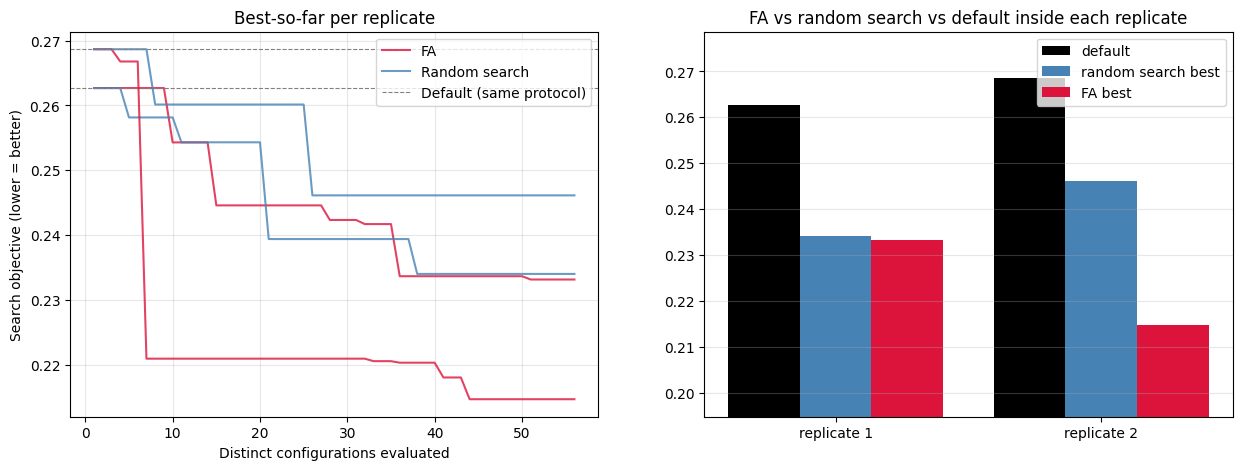

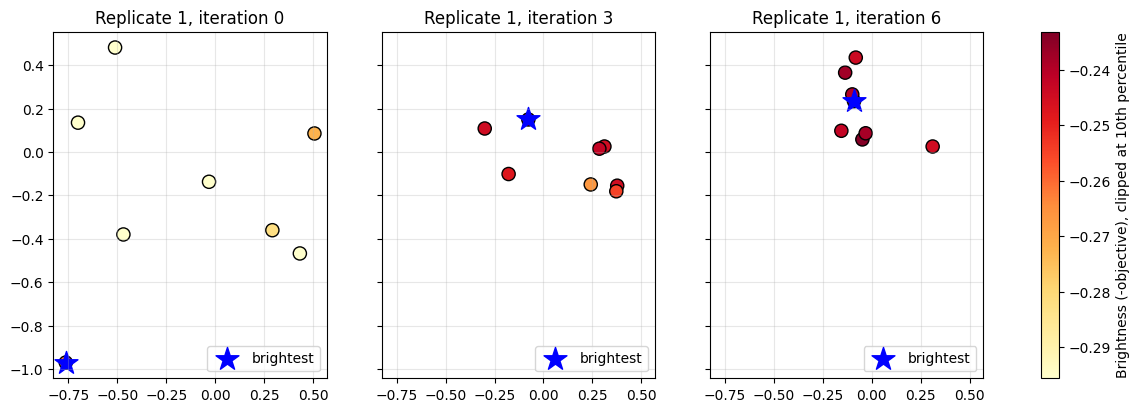

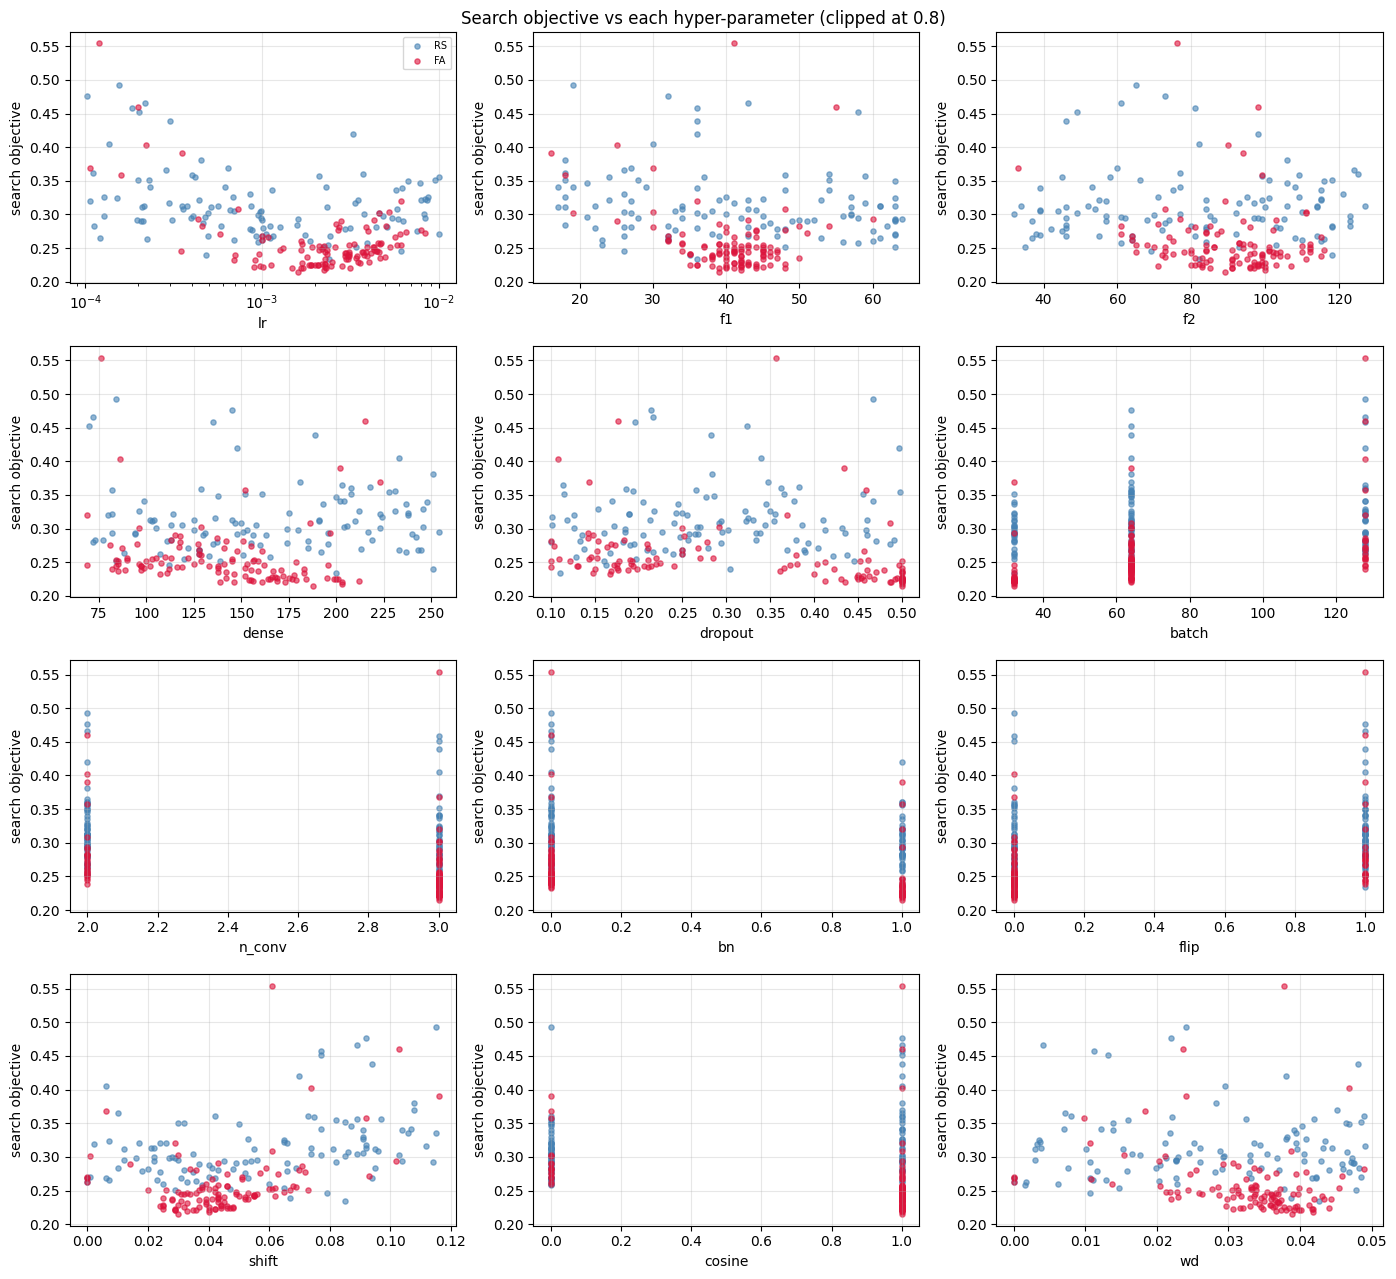

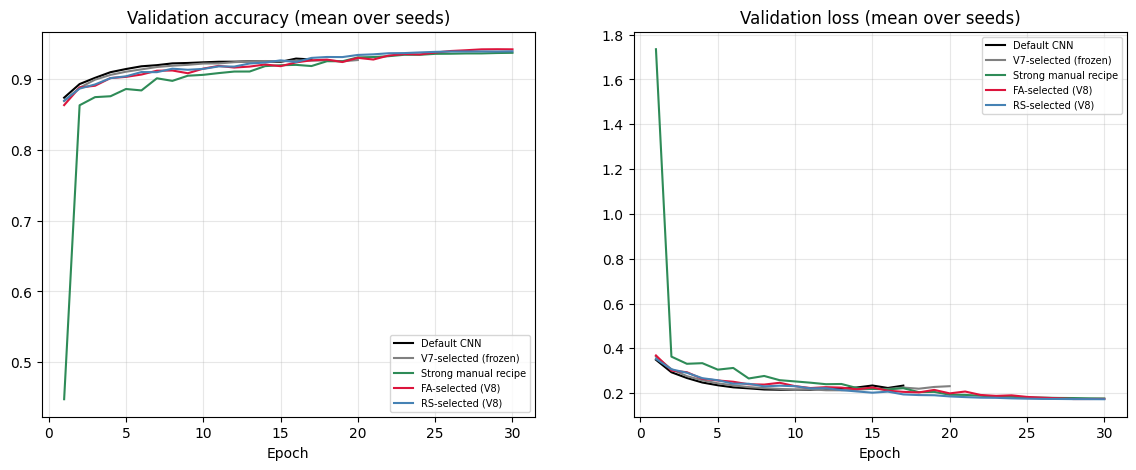

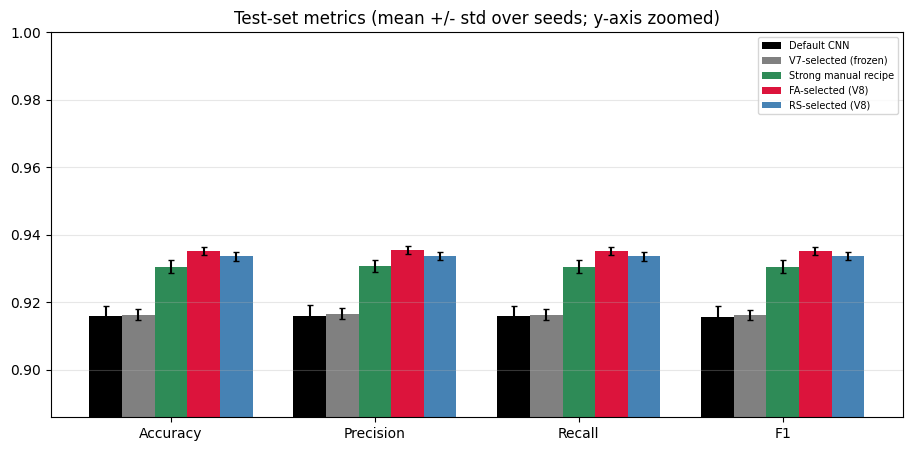

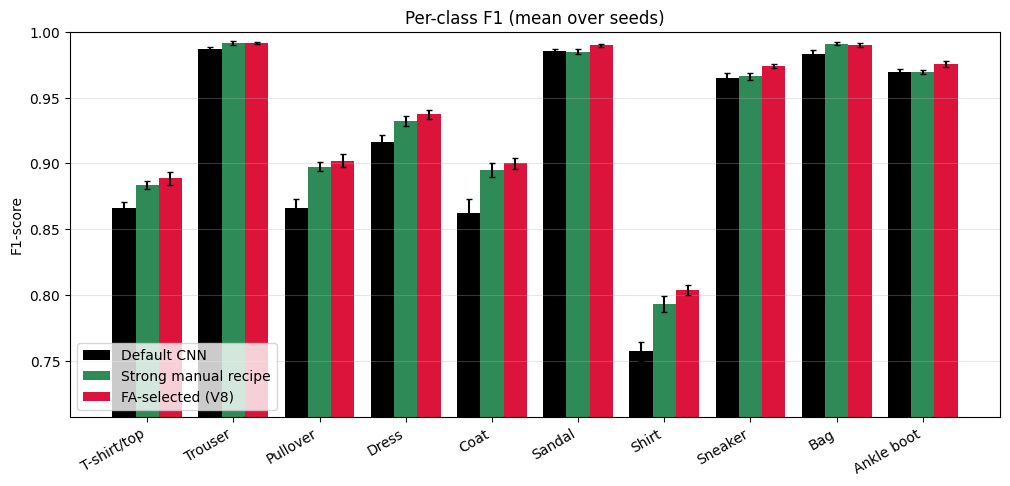

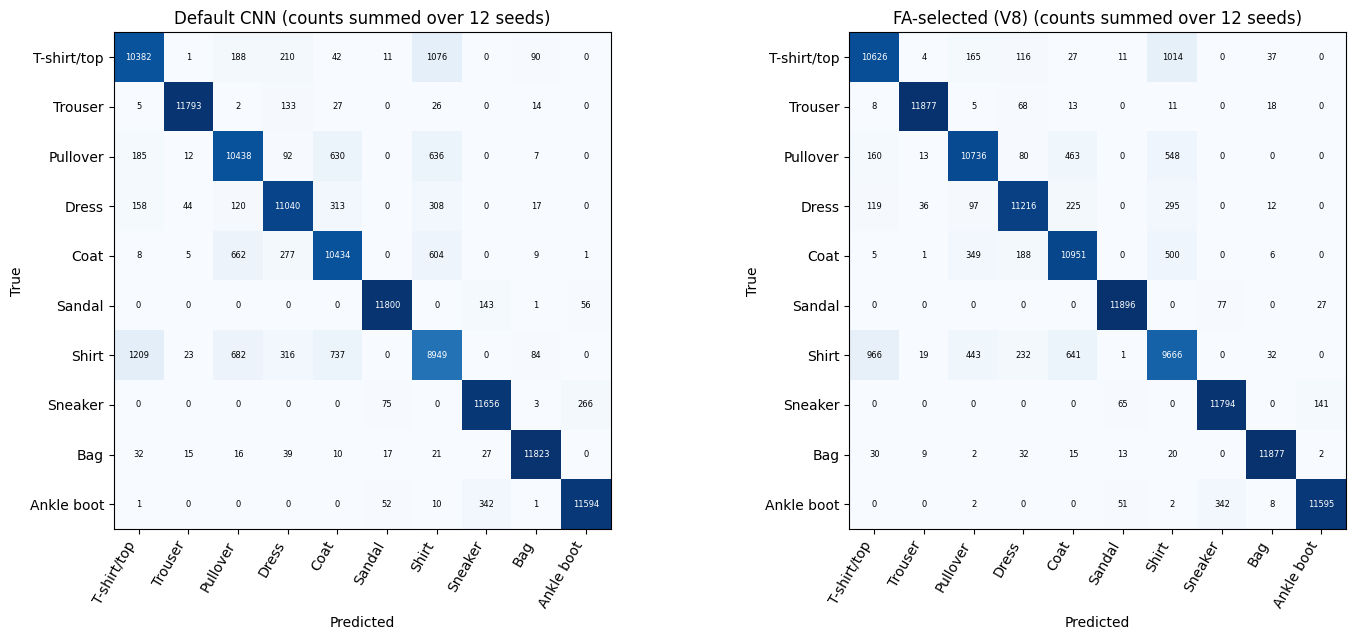

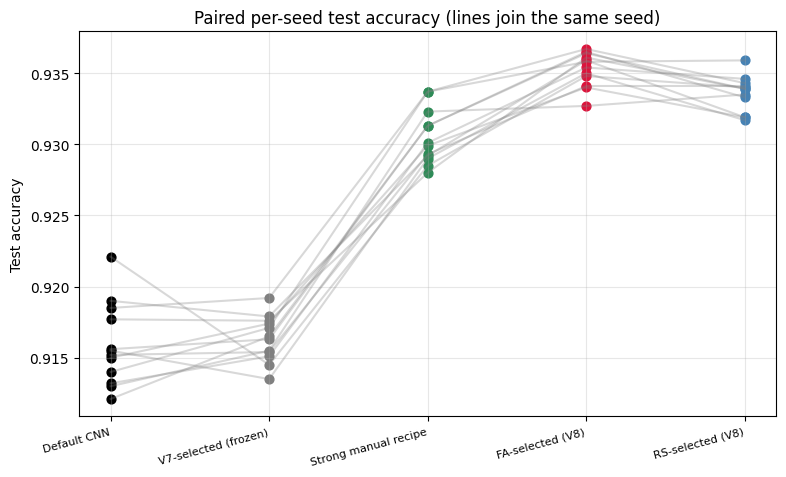

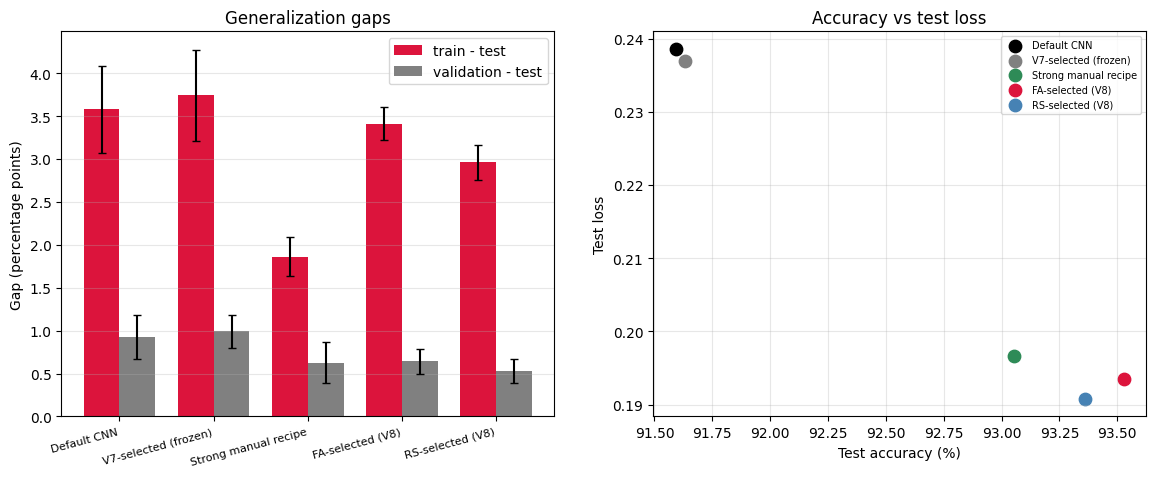

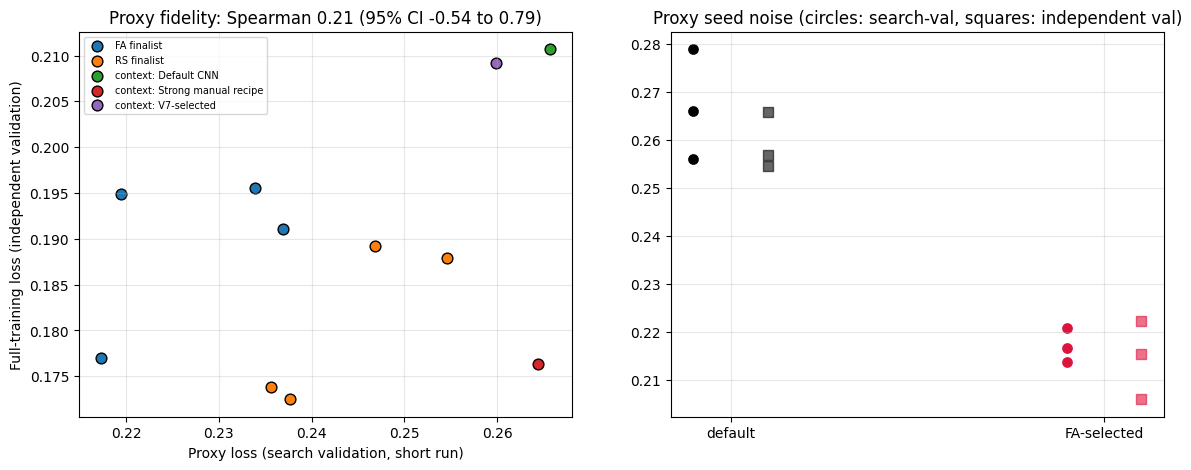

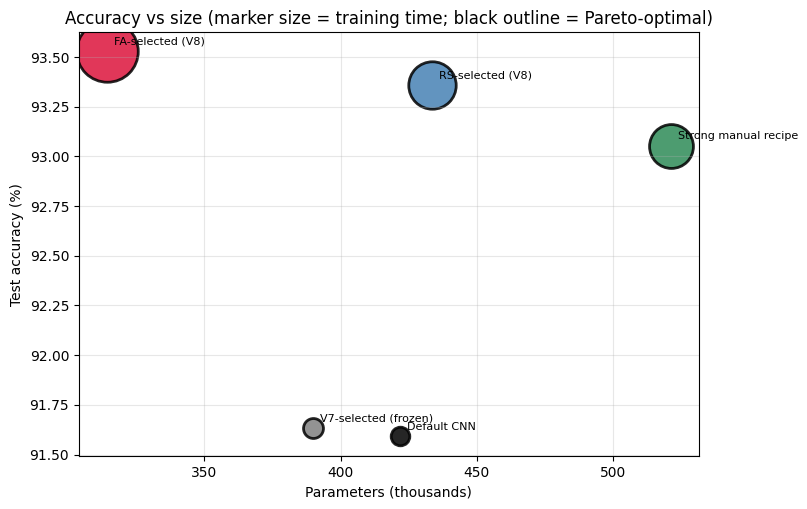

,acc,params,secs,pareto_optimal
Default CNN,91.591,421642.0,35.002,True
V7-selected (frozen),91.633,389964.0,41.508,True
Strong manual recipe,93.053,521098.0,239.475,True
FA-selected (V8),93.528,314331.0,480.046,True
RS-selected (V8),93.358,433489.0,281.511,True


In [13]:
def best_so_far(xs, fvals):
    seen, curve, best = set(), [], -np.inf
    for x, f in zip(xs, fvals):
        k = hp_key(x)
        if k in seen: continue
        seen.add(k); best = max(best, f); curve.append(-best)
    return np.array(curve)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for rp in reps:
    c_fa = best_so_far([e["x"] for e in rp["fa"]["eval_log"]], [e["fitness"] for e in rp["fa"]["eval_log"]])
    c_rs = best_so_far(rp["X_rand"], rp["f_rand"]); assert_finite("curves", np.concatenate([c_fa, c_rs]))
    axs[0].plot(np.arange(1, len(c_fa) + 1), c_fa, color="crimson", alpha=.8, label="FA" if rp["r"] == 0 else None)
    axs[0].plot(np.arange(1, len(c_rs) + 1), c_rs, color="steelblue", alpha=.8, label="Random search" if rp["r"] == 0 else None)
    axs[0].axhline(-rp["base_fit"], color="gray", ls="--", lw=.8, label="Default (same protocol)" if rp["r"] == 0 else None)
axs[0].set_xlabel("Distinct configurations evaluated"); axs[0].set_ylabel("Search objective (lower = better)")
axs[0].set_title("Best-so-far per replicate"); axs[0].legend(); axs[0].grid(alpha=.3)
w = 0.27; xs_ = np.arange(R)
for k, (vals, lab, c) in enumerate(([[-rp["base_fit"] for rp in reps], "default", "black"],
                                    [[-rp["f_rand"].max() for rp in reps], "random search best", "steelblue"],
                                    [[-rp["fa"]["best_f"] for rp in reps], "FA best", "crimson"])):
    axs[1].bar(xs_ + (k - 1) * w, vals, w, label=lab, color=c)
allv = [-rp["base_fit"] for rp in reps] + [-rp["f_rand"].max() for rp in reps] + [-rp["fa"]["best_f"] for rp in reps]
axs[1].set_ylim(min(allv) - 0.02, max(allv) + 0.01); axs[1].set_xticks(xs_); axs[1].set_xticklabels([f"replicate {i + 1}" for i in range(R)])
axs[1].set_title("FA vs random search vs default inside each replicate"); axs[1].legend(); axs[1].grid(axis="y", alpha=.3)
savefig("02_search_replicates")

allP = np.vstack(fa["pos_hist"]); assert_finite("positions", allP)
pca = PCA(2).fit(allP); allF = np.concatenate(fa["fit_hist"])
vmin = float(np.quantile(allF, 0.10)); vmax = float(allF.max())
snap = sorted(set([0, CFG["FA_ITERS"] // 2, CFG["FA_ITERS"]]))
fig, axs = plt.subplots(1, len(snap), figsize=(5 * len(snap), 4.5), sharex=True, sharey=True, squeeze=False); axs = axs[0]
for ax, k in zip(axs, snap):
    Zp = pca.transform(fa["pos_hist"][k]); F = fa["fit_hist"][k]; assert_finite(f"PCA {k}", Zp)
    sc = ax.scatter(Zp[:, 0], Zp[:, 1], c=np.clip(F, vmin, vmax), cmap="YlOrRd", vmin=vmin, vmax=vmax, s=90, edgecolor="k")
    b = int(F.argmax()); ax.scatter(Zp[b, 0], Zp[b, 1], marker="*", s=300, c="blue", label="brightest")
    ax.set_title(f"Replicate 1, iteration {k}"); ax.legend(loc="lower right"); ax.grid(alpha=.3)
fig.colorbar(sc, ax=list(axs), label="Brightness (-objective), clipped at 10th percentile")
savefig("03_firefly_movement")

dist = pd.concat([fa_all[fa_all.new_config].assign(method="FA"), rs_all.assign(method="RS", iteration=0)])
assert_finite("hp scatter", dist[HP_COLS + ["objective"]].to_numpy())
fig, axs = plt.subplots(4, 3, figsize=(14, 13))
for ax, c in zip(axs.ravel(), HP_COLS):
    for meth, col in (("RS", "steelblue"), ("FA", "crimson")):
        d_ = dist[dist.method == meth]; ax.scatter(d_[c], np.clip(d_["objective"], None, 0.8), s=14, alpha=.6, color=col, label=meth)
    if c == "lr": ax.set_xscale("log")
    ax.set_xlabel(c); ax.set_ylabel("search objective"); ax.grid(alpha=.3)
axs[0, 0].legend(fontsize=7); fig.suptitle("Search objective vs each hyper-parameter (clipped at 0.8)"); plt.tight_layout()
savefig("04_hyperparameter_vs_fitness")

def stack(hists, k):
    L = max(len(h[k]) for h in hists)
    return np.array([list(h[k]) + [np.nan] * (L - len(h[k])) for h in hists])
cols5 = ["black", "gray", "seagreen", "crimson", "steelblue"]
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for n, col in zip(names, cols5):
    for ax, key in ((axs[0], "val_accuracy"), (axs[1], "val_loss")):
        A = stack(finals[n]["hists"], key); mu = np.nanmean(A, 0); assert_finite("lc " + key, mu)
        ax.plot(np.arange(1, len(mu) + 1), mu, color=col, label=n)
axs[0].set_title("Validation accuracy (mean over seeds)"); axs[1].set_title("Validation loss (mean over seeds)")
for a in axs: a.set_xlabel("Epoch"); a.grid(alpha=.3); a.legend(fontsize=7)
savefig("05_learning_curves")
pd.DataFrame([dict(model=n, seed=s, epoch=e + 1, loss=h["loss"][e], val_loss=h["val_loss"][e], accuracy=h["accuracy"][e], val_accuracy=h["val_accuracy"][e])
              for n in names for s, h in zip(CFG["SEEDS"], finals[n]["hists"]) for e in range(len(h["loss"]))]).to_csv(f"{OUT}/learning_curves.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 5)); w = 0.16; xs = np.arange(4)
for k, (n, col) in enumerate(zip(names, cols5)):
    m = finals[n]["metrics"]; mu = [m[c].mean() for c in metric_cols[:4]]; sd = [m[c].std() for c in metric_cols[:4]]; assert_finite("bars", mu)
    ax.bar(xs + (k - 2) * w, mu, w, yerr=sd, capsize=2, color=col, label=n)
lo = min(finals[n]["metrics"].accuracy.mean() for n in names) - 0.03
ax.set_ylim(lo, 1.0); ax.set_xticks(xs); ax.set_xticklabels([c.capitalize() for c in metric_cols[:4]])
ax.set_title("Test-set metrics (mean +/- std over seeds; y-axis zoomed)"); ax.legend(fontsize=7); ax.grid(axis="y", alpha=.3)
savefig("06_metric_comparison")

def per_class_f1(n):
    return np.array([precision_recall_fscore_support(y_test, p, zero_division=0)[2] for p in finals[n]["preds"]])
pcs = {n: per_class_f1(n) for n in ("Default CNN", "Strong manual recipe", "FA-selected (V8)")}
fig, ax = plt.subplots(figsize=(12, 5)); xs = np.arange(10)
for k, (n, col) in enumerate(zip(pcs, ("black", "seagreen", "crimson"))):
    ax.bar(xs + (k - 1) * 0.27, pcs[n].mean(0), 0.27, yerr=pcs[n].std(0), capsize=2, color=col, label=n)
ax.set_xticks(xs); ax.set_xticklabels(CLASS_NAMES, rotation=30, ha="right")
ax.set_ylim(max(0, min(v.mean(0).min() for v in pcs.values()) - .05), 1); ax.set_ylabel("F1-score"); ax.legend(); ax.grid(axis="y", alpha=.3)
ax.set_title("Per-class F1 (mean over seeds)"); savefig("07_per_class_f1")
pd.DataFrame([dict(model=n, cls=CLASS_NAMES[c], f1_mean=v.mean(0)[c], f1_std=v.std(0)[c]) for n, v in pcs.items() for c in range(10)]).to_csv(f"{OUT}/per_class_metrics.csv", index=False)

fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, n in zip(axs, ("Default CNN", "FA-selected (V8)")):
    cm = sum(confusion_matrix(y_test, p, labels=list(range(10))) for p in finals[n]["preds"]); cmn = cm / cm.sum(1, keepdims=True); assert_finite("cm", cmn)
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(f"{OUT}/confusion_matrix_{n.split()[0].lower()}.csv")
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(10):
        for j in range(10):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=6, color="white" if cmn[i, j] > .5 else "black")
    ax.set_xticks(range(10)); ax.set_yticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=60, ha="right"); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{n} (counts summed over {len(CFG['SEEDS'])} seeds)")
plt.tight_layout(); savefig("08_confusion_matrices")

fig, ax = plt.subplots(figsize=(9, 5))
for k, (n, col) in enumerate(zip(names, cols5)):
    ax.scatter(np.full(len(CFG["SEEDS"]), k), finals[n]["metrics"].accuracy, color=col, s=40)
for s in range(len(CFG["SEEDS"])):
    ax.plot(range(len(names)), [finals[n]["metrics"].accuracy.iloc[s] for n in names], color="gray", alpha=.3)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=15, ha="right", fontsize=8); ax.set_ylabel("Test accuracy")
ax.set_title("Paired per-seed test accuracy (lines join the same seed)"); ax.grid(alpha=.3); savefig("09_per_seed_accuracy")

fig, axs = plt.subplots(1, 2, figsize=(14, 5)); xs = np.arange(len(names))
for k, (c, lab, col) in enumerate((("gap_train_test", "train - test", "crimson"), ("gap_val_test", "validation - test", "gray"))):
    mu = [100 * finals[n]["metrics"][c].mean() for n in names]; sd = [100 * finals[n]["metrics"][c].std() for n in names]
    axs[0].bar(xs + (k - .5) * .38, mu, .38, yerr=sd, capsize=3, label=lab, color=col)
axs[0].set_xticks(xs); axs[0].set_xticklabels(names, rotation=15, ha="right", fontsize=8); axs[0].set_ylabel("Gap (percentage points)")
axs[0].set_title("Generalization gaps"); axs[0].legend(); axs[0].grid(axis="y", alpha=.3)
for n, col in zip(names, cols5):
    axs[1].scatter(finals[n]["metrics"].accuracy.mean() * 100, finals[n]["metrics"].test_loss.mean(), s=80, color=col, label=n)
axs[1].set_xlabel("Test accuracy (%)"); axs[1].set_ylabel("Test loss"); axs[1].set_title("Accuracy vs test loss"); axs[1].legend(fontsize=7); axs[1].grid(alpha=.3)
savefig("11_generalization_gaps")

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
assert_finite("fidelity", fid[["proxy_val_loss", "full_val_loss"]].to_numpy())
for role, d in fid.groupby("role"):
    axs[0].scatter(d.proxy_val_loss, d.full_val_loss, s=60, label=role, edgecolor="k")
axs[0].set_xlabel("Proxy loss (search validation, short run)"); axs[0].set_ylabel("Full-training loss (independent validation)")
axs[0].set_title(f"Proxy fidelity: Spearman {rho:.2f} (95% CI {rho_ci[0]:.2f} to {rho_ci[1]:.2f})"); axs[0].grid(alpha=.3); axs[0].legend(fontsize=7)
for k, (name, col) in enumerate((("default", "black"), ("FA-selected", "crimson"))):
    d = noise[noise.config == name]
    axs[1].scatter(np.full(len(d), k - .1), d.search_val_loss, color=col, s=45)
    axs[1].scatter(np.full(len(d), k + .1), d.independent_val_loss, color=col, s=45, marker="s", alpha=.6)
axs[1].set_xticks([0, 1]); axs[1].set_xticklabels(["default", "FA-selected"]); axs[1].set_title("Proxy seed noise (circles: search-val, squares: independent val)"); axs[1].grid(alpha=.3)
savefig("12_proxy_diagnostics")

mm = pd.DataFrame({n: dict(acc=finals[n]["metrics"].accuracy.mean() * 100, params=float(finals[n]["metrics"].params.iloc[0]),
                           secs=finals[n]["metrics"].train_seconds.mean()) for n in names}).T
def dominated(i):
    return any((mm.acc.iloc[j] >= mm.acc.iloc[i] and mm.params.iloc[j] <= mm.params.iloc[i] and mm.secs.iloc[j] <= mm.secs.iloc[i] and
                (mm.acc.iloc[j] > mm.acc.iloc[i] or mm.params.iloc[j] < mm.params.iloc[i] or mm.secs.iloc[j] < mm.secs.iloc[i])) for j in range(len(mm)) if j != i)
mm["pareto_optimal"] = [not dominated(i) for i in range(len(mm))]; mm.to_csv(f"{OUT}/pareto_analysis.csv")
fig, ax = plt.subplots(figsize=(8, 5.5))
for (n, r_), col in zip(mm.iterrows(), cols5):
    ax.scatter(r_.params / 1000, r_.acc, s=40 + 4 * r_.secs, color=col, edgecolor="k" if r_.pareto_optimal else "none", linewidth=2, alpha=.85)
    ax.annotate(n, (r_.params / 1000, r_.acc), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Parameters (thousands)"); ax.set_ylabel("Test accuracy (%)"); ax.grid(alpha=.3)
ax.set_title("Accuracy vs size (marker size = training time; black outline = Pareto-optimal)"); savefig("14_pareto")
display(mm.round(3))

### 6.1 Conclusion (generated from the measured numbers, using the pre-declared rules)

In [14]:
def verdict_for(row):
    if row.n_seeds < 5: return "INSUFFICIENT SEEDS (need >= 5 for a verdict)"
    if row.ci95_low_pp > 0 and row.holm_p_primary < 0.05: return "reliably BETTER"
    if row.ci95_high_pp < 0 and row.holm_p_primary < 0.05: return "reliably WORSE"
    if not np.isnan(row.tost_p) and row.tost_p < 0.05: return f"EQUIVALENT within +/-{CFG['EQUIV_MARGIN_PP']} pp"
    return "INCONCLUSIVE (no reliable difference)"

print("FINAL EXPERIMENT SUMMARY (test accuracy, mean +/- std over seeds)")
for n in names:
    m = finals[n]["metrics"]
    print(f"{n:24s} | acc {m.accuracy.mean():.4f} +/- {m.accuracy.std():.4f} | macro-F1 {m.f1.mean():.4f} | test loss {m.test_loss.mean():.4f} | params {int(m.params.iloc[0])} | {m.train_seconds.mean():.0f}s")
verdicts = {}
for a, b in PRIMARY:
    r_ = pw[pw.comparison.isin([f"{a} - {b}", f"{b} - {a}"])].iloc[0]
    sign = 1 if r_.comparison == f"{a} - {b}" else -1
    rr = r_.copy(); rr.mean_diff_pp *= sign
    lo, hi = (r_.ci95_low_pp, r_.ci95_high_pp) if sign == 1 else (-r_.ci95_high_pp, -r_.ci95_low_pp); rr.ci95_low_pp, rr.ci95_high_pp = lo, hi
    verdicts[f"{a} vs {b}"] = dict(diff_pp=float(rr.mean_diff_pp), ci95=[float(lo), float(hi)], holm_p=float(r_.holm_p_primary),
                                   tost_p=float(r_.tost_p), verdict=verdict_for(rr))
    print(f"\n{a} - {b}: {rr.mean_diff_pp:+.2f} pp, 95% CI [{lo:+.2f}, {hi:+.2f}], Holm p = {r_.holm_p_primary:.4f}, TOST p = {r_.tost_p:.4f} -> {verdicts[f'{a} vs {b}']['verdict']}")
print("\nSelected FA configuration:", FA_BEST_HP); print("Selected RS configuration:", RS_BEST_HP)
print(f"Search: FA {fa_minutes:.0f} min, RS {rs_minutes:.0f} min, re-ranking {rerank_minutes:.0f} min | proxy epochs trained (per replicate, FA vs RS): "
      f"{[(rp['fa_epochs'], rp['rs_epochs']) for rp in reps]}")
print(f"Proxy fidelity Spearman {rho:.2f} | proxy noise SD {noise_sd:.4f} | landscape CV R^2: {r2}")

FINAL EXPERIMENT SUMMARY (test accuracy, mean +/- std over seeds)
Default CNN              | acc 0.9159 +/- 0.0029 | macro-F1 0.9157 | test loss 0.2386 | params 421642 | 35s
V7-selected (frozen)     | acc 0.9163 +/- 0.0016 | macro-F1 0.9161 | test loss 0.2369 | params 389964 | 42s
Strong manual recipe     | acc 0.9305 +/- 0.0019 | macro-F1 0.9305 | test loss 0.1967 | params 521098 | 239s
FA-selected (V8)         | acc 0.9353 +/- 0.0012 | macro-F1 0.9353 | test loss 0.1935 | params 314331 | 480s
RS-selected (V8)         | acc 0.9336 +/- 0.0012 | macro-F1 0.9336 | test loss 0.1908 | params 433489 | 282s

FA-selected (V8) - Default CNN: +1.94 pp, 95% CI [+1.77, +2.09], Holm p = 0.0000, TOST p = 1.0000 -> reliably BETTER

FA-selected (V8) - Strong manual recipe: +0.48 pp, 95% CI [+0.36, +0.59], Holm p = 0.0000, TOST p = 0.3497 -> reliably BETTER

FA-selected (V8) - RS-selected (V8): +0.17 pp, 95% CI [+0.09, +0.25], Holm p = 0.0027, TOST p = 0.0000 -> reliably BETTER

Selected FA configurat

## 7. Acceptance checks and exports

In [15]:
png_expected = ["00_toy_benchmarks", "01_dataset_overview", "02_search_replicates", "03_firefly_movement", "04_hyperparameter_vs_fitness",
                "05_learning_curves", "06_metric_comparison", "07_per_class_f1", "08_confusion_matrices", "09_per_seed_accuracy",
                "11_generalization_gaps", "12_proxy_diagnostics", "14_pareto"]
numeric = pd.concat([finals[n]["metrics"] for n in names]).select_dtypes("number").to_numpy(dtype=float)
frozen_ts = json.load(open(f"{OUT}/frozen_selection.json"))["created_ts"]
_t0 = time.time(); memo("selftest", dict(a=1), lambda: 1); memo("selftest", dict(a=1), lambda: 1 / 0)   # second call must come from disk
checks = {
    "real_run_not_smoke": not SMOKE,
    "firefly_unit_tests_passed": all(unit.values()),
    "toy_benchmarks_ran": len(toy) == 3,
    "dataset_is_fashion_mnist_shape": X_train.shape[1:] == (28, 28, 1) and (SMOKE or len(X_full) == 60000),
    "search_subset_disjoint_from_search_val": not set(pos_sub) & set(pos_sval),
    "search_data_disjoint_from_official_validation": not set(idx_train[pos_sub]) & set(idx_val) and not set(idx_train[pos_sval]) & set(idx_val),
    "seeds_disjoint (eval vs selection/noise)": not (set(CFG["SELECT_SEEDS"]) | set(CFG["NOISE_SEEDS"])) & set(CFG["SEEDS"]),
    "fa_rs_matched_distinct_budgets": all(rp["n_fa"] == rp["n_rs"] for rp in reps),
    "all_replicates_completed": len(reps) == R and R >= 1,
    "selection_frozen_before_test": (TEST["first_eval_ts"] is None) or (frozen_ts <= TEST["first_eval_ts"]),
    "same_seeds_for_all_models": all(list(finals[n]["metrics"].seed) == list(CFG["SEEDS"]) for n in names),
    "all_final_metrics_finite": bool(np.isfinite(numeric).all()),
    "holm_correction_applied": bool(pw.holm_p_primary.notna().sum() == len(PRIMARY)) or SMOKE,
    "checkpoint_recovery_works": len(os.listdir(CKPT)) > 0,
    "all_figures_saved": all(os.path.getsize(f"{OUT}/{p}.png") > 10_000 for p in png_expected),
}
for k, v in checks.items():
    print(("PASS " if v else "FAIL ") + k)

report_numbers = dict(
    models={n: dict(accuracy_mean=float(finals[n]["metrics"].accuracy.mean()), accuracy_std=float(finals[n]["metrics"].accuracy.std()),
                    f1_mean=float(finals[n]["metrics"].f1.mean()), test_loss_mean=float(finals[n]["metrics"].test_loss.mean()),
                    params=int(finals[n]["metrics"].params.iloc[0]), train_seconds=float(finals[n]["metrics"].train_seconds.mean()),
                    hyperparameters=MODELS[n]) for n in names},
    primary_comparisons=verdicts, equivalence_margin_pp=CFG["EQUIV_MARGIN_PP"],
    proxy=dict(spearman=rho, spearman_ci95=list(rho_ci), noise_sd=noise_sd, fa_advantage_on_proxy=gap_proxy, landscape_cv_r2=r2),
    toy_benchmarks=toy.to_dict(orient="records"),
    search=dict(replicates=R, fa_minutes=fa_minutes, rs_minutes=rs_minutes, rerank_minutes=rerank_minutes,
                proxy_epochs=[dict(fa=rp["fa_epochs"], rs=rp["rs_epochs"]) for rp in reps]))
json.dump(report_numbers, open(f"{OUT}/report_numbers.json", "w"), indent=2, default=float)
json.dump(dict(checks=checks, all_passed=bool(all(checks.values()))), open(f"{OUT}/run_manifest.json", "w"), indent=2)
with open(f"{OUT}/results_summary.md", "w") as fh:
    fh.write("# V8 results summary (auto-generated)\n\n## Test metrics\n```\n" + summary.to_string() + "\n```\n\n## Pairwise tests (pp)\n```\n" + pw.round(4).to_string() +
             "\n```\n\n## Generalization\n```\n" + gen.to_string() + "\n```\n\n## Toy benchmarks\n```\n" + toy.round(6).to_string() + "\n```\n")
if not all(checks.values()):
    print("\nWARNING: some acceptance checks failed -- do NOT use these outputs for the report until fixed.")
shutil.make_archive("fashion_firefly_results_v8", "zip", OUT)
print("\nSaved files:", sorted(f for f in os.listdir(OUT) if f != "ckpt"))
try:
    from google.colab import files; files.download("fashion_firefly_results_v8.zip")
except Exception:
    print("Not on Colab: results are in ./results and fashion_firefly_results_v8.zip")

PASS real_run_not_smoke
PASS firefly_unit_tests_passed
PASS toy_benchmarks_ran
PASS dataset_is_fashion_mnist_shape
PASS search_subset_disjoint_from_search_val
PASS search_data_disjoint_from_official_validation
FAIL seeds_disjoint (eval vs selection/noise)
PASS fa_rs_matched_distinct_budgets
PASS all_replicates_completed
PASS selection_frozen_before_test
PASS same_seeds_for_all_models
PASS all_final_metrics_finite
PASS holm_correction_applied
PASS checkpoint_recovery_works
PASS all_figures_saved


Saved files: ['00_toy_benchmarks.png', '01_dataset_overview.png', '02_search_replicates.png', '03_firefly_movement.png', '04_hyperparameter_vs_fitness.png', '05_learning_curves.png', '06_metric_comparison.png', '07_per_class_f1.png', '08_confusion_matrices.png', '09_per_seed_accuracy.png', '11_generalization_gaps.png', '12_proxy_diagnostics.png', '14_pareto.png', 'confusion_matrix_default.csv', 'confusion_matrix_fa-selected.csv', 'environment.json', 'fa_evaluations.csv', 'firefly_log.csv', 'fi

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>